<a href="https://colab.research.google.com/github/LucasBrignoli/tp-mineria-datos-shein/blob/main/TP_Mineria_Datos_Shein.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP Explotación de la Información (Minería de Datos)
## ¿Qué distingue a un producto caro de uno barato? — Análisis del dataset *Dirty E-Commerce Data (SHEIN)*

**Materia:** **Aprendizaje de Máquina y Minería de Datos**  |  **Universidad Nacional de Lanús** |
**Integrantes:** **Martín Hildebrandt, Julián Castro, Roberto Gonzalez, Lucas Ivan Brignoli**

### Idea del trabajo
Usamos el dataset Dirty E-Commerce Data de Kaggle, que contiene productos de la tienda online SHEIN de Estados Unidos. Hay un archivo por categoría, pero nosotros juntamos todos en uno solo, incluyendo ropa, calzado, electrodomésticos, productos para mascotas, juguetes, herramientas y más. En total, tenemos más de 70.000 productos, con precios que van desde menos de un dólar hasta muebles de más de 2.000 dólares.

El dataset viene con datos desordenados a propósito. Por ejemplo, los precios, descuentos y ventas aparecen como texto ($2.03, -22%, 5.6k+ sold recently), hay productos duplicados, títulos repartidos en dos columnas, celdas vacías y hasta un registro de prueba con un precio de 888.888 dólares.

Una vez que limpiamos los datos, buscamos responder dos preguntas:

1. K-Means: queremos ver qué grupos de productos aparecen si tenemos en cuenta el precio en relación con su categoría, el descuento, las ventas y el largo del título. También buscamos comprobar si esos grupos coinciden con las categorías de la tienda o si mezclan productos de distintas categorías.

2. Red neuronal con retropropagación: queremos comprobar si podemos predecir si un producto es barato, medio o caro sin utilizar su precio directamente. Para eso, usamos solamente el título, el descuento, las ventas y si aparece como Best Seller. También buscamos identificar cuáles de esos datos ayudan más a hacer la predicción.

### Técnicas aplicadas
| Técnica | Tipo | Para qué la usamos |
|---|---|---|
| **K-Means** | No supervisada| Agrupar productos según sus características, sin definir los grupos de antemano |
| **Red neuronal con retropropagación** | Supervisada | Predecir si un producto es barato, medio o caro y ver qué datos influyen más en la predicción. |

### Estructura del Colab

El notebook está dividido en varias partes. Primero obtenemos los datos y los preparamos para trabajar con ellos. Después, los exploramos con gráficos, aplicamos K-Means y entrenamos la red neuronal. Por último, analizamos los resultados, sacamos las conclusiones y preparamos el video de defensa.

Para ejecutarlo, entramos a Google Colab y seleccionamos Entorno de ejecución → Ejecutar todo. El notebook descarga automáticamente los datos desde Kaggle usando `kagglehub`.

Si la descarga falla, podemos subir los archivos CSV a una carpeta de Colab y escribir la ruta donde están guardados en `RUTA_DATOS`, dentro de la sección 1.

La ejecución puede tardar varios minutos porque la red neuronal tiene que entrenarse con decenas de miles de productos.

###  Glosario rápido (para consultar durante la defensa)
| Término | Qué significa, en simple |
|---|---|
| **Dato sucio** | Dato con errores de formato, faltantes, repetidos o imposibles. Hay que limpiarlo antes de analizar. |
| **Mediana** | El valor del medio: la mitad de los datos queda por debajo y la mitad por encima. No se deja engañar por unos pocos valores gigantes. |
| **Escala logarítmica / log1p** | Comprime números muy dispersos (de menos de 1 a más de 2.000) para poder compararlos. Cada paso vale ×10. |
| **Correlación de Spearman** | Número entre -1 y 1: cerca de 1 = suben juntas, cerca de 0 = no se relacionan, cerca de -1 = una sube cuando la otra baja. **Correlación no es causa.** |
| **Imputar** | Rellenar un dato faltante con un valor razonable. |
| **Estandarizar** | Pasar variables de distintas unidades a una escala común para compararlas. |
| **Cluster** | Grupo de elementos parecidos entre sí. |
| **Inercia / Silueta** | Inercia: qué tan compactos son los grupos (menor = mejor). Silueta: de -1 a 1, qué tan separados están (más alto = mejor). |
| **PCA** | Técnica que "aplasta" muchas variables en 2 para poder dibujarlas en un plano. |
| **Red neuronal (MLP)** | Modelo formado por capas de "neuronas" conectadas. Cada conexión tiene un peso que se ajusta aprendiendo. |
| **Retropropagación** | Cómo aprende la red: calcula el error de su predicción y lo "propaga hacia atrás" para corregir los pesos de cada capa. |
| **Época** | Una pasada completa de la red por todos los datos de entrenamiento. |
| **Pérdida (loss)** | Número que mide cuánto se equivoca la red. Aprender = hacer que baje. |
| **Accuracy / Baseline** | Accuracy: % de aciertos. Baseline: lo que acertaría un modelo "tonto" que responde siempre la clase más común. |
| **Sobreajuste** | El modelo se aprende los datos de memoria y falla con datos nuevos. |

## 0. Preparación del entorno
En esta parte importamos las librerías que vamos a usar y definimos los colores y algunas funciones que nos ayudan a crear los gráficos.

También fijamos una semilla (SEED = 42) para que los resultados de K-Means, la muestra de datos y la red neuronal se puedan reproducir en distintas ejecuciones. Además, usamos distintos tonos de azul para representar los niveles de precio, desde el más claro para los productos baratos hasta el más oscuro para los caros. Así mantenemos los mismos colores en todos los gráficos y es más fácil interpretar los resultados.

In [ ]:
# =====================================================================
# 0. PREPARACIÓN DEL ENTORNO
# Importamos librerías, definimos colores y funciones de ayuda para los gráficos.
# =====================================================================

# --- Librerías generales ---
import re, glob, os                      # re: expresiones regulares | glob: buscar archivos | os: rutas de archivos
import numpy as np                       # cálculos numéricos
import pandas as pd                      # manejo de tablas (DataFrames)
import matplotlib.pyplot as plt          # gráficos
import seaborn as sns                    # gráficos estadísticos (mapas de calor)
from matplotlib.colors import LinearSegmentedColormap   # para crear escalas de color propias
from matplotlib.patches import Patch                    # para armar leyendas a mano
from matplotlib.ticker import FuncFormatter, NullFormatter   # para dar formato a los números de los ejes
from IPython.display import display      # muestra tablas prolijas dentro de Colab

# --- Herramientas de scikit-learn (machine learning) ---
from sklearn.preprocessing import StandardScaler                      # estandariza variables (media 0, desvío 1)
from sklearn.compose import ColumnTransformer                         # aplica un tratamiento distinto a cada grupo de columnas
from sklearn.pipeline import Pipeline                                 # encadena preparación + modelo en un solo objeto
from sklearn.feature_extraction.text import CountVectorizer           # convierte texto en columnas de palabras (0/1)
from sklearn.cluster import KMeans                                    # algoritmo de clustering (técnica 1)
from sklearn.decomposition import PCA                                 # reduce dimensiones para poder graficar
from sklearn.neural_network import MLPClassifier                      # red neuronal con retropropagación (técnica 2)
from sklearn.inspection import permutation_importance                 # mide qué variables usa más el modelo
from sklearn.metrics import silhouette_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, f1_score   # métricas de evaluación
from sklearn.model_selection import train_test_split, cross_val_score # separar entrenamiento/prueba y validación cruzada
from sklearn.dummy import DummyClassifier                             # modelo "tonto" para comparar (baseline)

# --- Configuración general ---
import warnings
warnings.filterwarnings("ignore")              # ocultamos advertencias para que la salida quede limpia
pd.set_option("display.max_columns", 30)       # mostrar hasta 30 columnas en las tablas
pd.set_option("display.max_colwidth", 70)      # cortar los textos largos a 70 caracteres

# --- Estilo de gráficos (paleta consistente en todo el notebook) ---
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"   # colores principales
# Estilo por defecto de todos los gráficos: fondo claro, sin bordes arriba/derecha, grilla suave, títulos en negrita
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781", "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "lines.linewidth": 2,
})
SEC = LinearSegmentedColormap.from_list("sec", ["#cde2fb", "#3987e5", "#0d366b"])   # secuencial (claro = poco, oscuro = mucho)
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])   # divergente (azul = negativo, rojo = positivo)
NIVEL_COL = {"Barato": "#86b6ef", "Medio": "#3987e5", "Caro": "#184f95"}              # ordinal: nivel de precio
CL_COLORS = [AZUL, NARANJA, AQUA, "#8e5bd9", GRIS]                                     # colores de los clusters
SEED = 42   # semilla: garantiza resultados reproducibles

# --- Funciones de formato para números y textos ---
miles = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))   # eje con separador de miles: 100000 -> 100.000
def num(n):                      # lo mismo pero para imprimir: num(82105) -> "82.105"
    return f"{n:,.0f}".replace(",", ".")
def esc(s):                      # matplotlib interpreta $...$ como fórmula: lo escapamos en los rótulos
    return str(s).replace("$", r"\$")
precio_fmt = FuncFormatter(lambda v, _: esc(f"${v:,.0f}".replace(",", ".")))   # eje de precios: 1000 -> $1.000
PALABRAS = r"(?u)\b[a-zA-Z][a-zA-Z]+\b"      # solo palabras de 2+ letras (ignora números y símbolos)

## 1. Obtención de datos
En esta parte descargamos los 20 archivos CSV de SHEIN, uno por cada categoría, y los juntamos en una sola tabla. También revisamos cómo vienen los datos originalmente, antes de hacer cualquier modificación.

Leemos todas las columnas como texto (`dtype=str`), porque los datos vienen desordenados y, si dejamos que pandas interprete los tipos automáticamente, podría convertir algunos valores de forma incorrecta. Por eso, nos encargamos de convertir los números más adelante, durante el preprocesamiento.

Además, agregamos una columna llamada `categoria`, donde guardamos el nombre de cada archivo, como `appliances`, `shoes` o `pet supplies`. Esto nos permite identificar de qué categoría viene cada producto.

Como los archivos no tienen exactamente las mismas columnas, algunos incluyen datos que otros no tienen, como `color-count` o columnas relacionadas con el `blackfridaybelts-...`. También hay archivos a los que les faltan datos de ranking o ventas. Para revisar estas diferencias, mostramos una tabla con las columnas disponibles en cada archivo.

Para obtener los datos tenemos dos opciones
- **Opción A (automática):** `kagglehub` descarga todo el dataset desde Kaggle.
- **Opción B (manual):** subir los CSV a una carpeta de Colab (panel de archivos de la izquierda) y escribir la ruta de esa carpeta en `RUTA_DATOS`.

In [ ]:
# =====================================================================
# 1. OBTENCIÓN DE DATOS: ubicar los archivos CSV del dataset
# =====================================================================

# Opción B (manual): si subiste los CSV a una carpeta de Colab, escribí acá su ruta. Ej.: "/content/shein"
RUTA_DATOS = None

# Si no se indicó una ruta manual, se descarga el dataset desde Kaggle
if RUTA_DATOS is None:
    # Opción A (automática): descarga de todo el dataset desde Kaggle
    try:
        import kagglehub                  # librería oficial de Kaggle para bajar datasets
    except ImportError:
        %pip install -q kagglehub         # si no está instalada, la instalamos
        import kagglehub
    RUTA_DATOS = kagglehub.dataset_download("oleksiimartusiuk/e-commerce-data-shein")   # devuelve la carpeta donde quedó

# Armamos la lista de archivos a leer:
if os.path.isfile(RUTA_DATOS):
    archivos = [RUTA_DATOS]               # si la ruta es un solo archivo, usamos solo ese
else:
    # si es una carpeta, buscamos todos los .csv adentro (también en subcarpetas)
    archivos = sorted(glob.glob(os.path.join(RUTA_DATOS, "**", "*.csv"), recursive=True))
print("Archivos CSV encontrados:", len(archivos))
if not archivos:                          # si no se encontró ninguno, cortamos con un error claro
    raise FileNotFoundError("No hay CSV en esa ruta. Revisar RUTA_DATOS.")

100%|██████████| 3.44M/3.44M [00:00<00:00, 37.4MB/s]

Extracting files...


Archivos CSV encontrados: 21


In [ ]:
# Leemos cada CSV, le agregamos su categoría y los juntamos en una sola tabla llamada "raw" (datos crudos)

def normalizar(nombre):                       # "goods-title-link--jump" -> "goods_title_link_jump"
    # pasa a minúsculas y reemplaza todo lo que no sea letra o número por "_",
    # así las columnas se llaman igual en todos los archivos
    return re.sub(r"[^a-z0-9]+", "_", str(nombre).strip().lower()).strip("_")

def categoria_de(ruta):                       # "us-shein-appliances-3987.csv" -> "appliances"
    n = os.path.splitext(os.path.basename(ruta))[0].lower()   # nombre del archivo sin carpeta ni ".csv"
    n = re.sub(r"^us[-_]shein[-_]", "", n)                     # sacamos el prefijo "us-shein-"
    n = re.sub(r"[-_]\d+$", "", n)                             # sacamos el número final "-3987"
    return re.sub(r"[-_]+", " ", n).strip()                    # guiones -> espacios

def leer_csv(ruta):                           # todo como texto; si no es UTF-8 probamos latin-1
    for enc in ("utf-8", "latin-1"):          # probamos dos codificaciones de caracteres
        try:
            # dtype=str: todo como texto (lo convertimos nosotros después)
            # on_bad_lines="skip": saltea filas mal formadas en vez de fallar
            return pd.read_csv(ruta, dtype=str, encoding=enc, on_bad_lines="skip", low_memory=False)
        except UnicodeDecodeError:
            continue                          # si falla con esta codificación, probamos la siguiente
    raise

partes, resumen = [], []                      # partes: una tabla por archivo | resumen: datos de control
for ruta in archivos:
    d = leer_csv(ruta)
    d.columns = [normalizar(c) for c in d.columns]   # unificamos nombres de columnas
    d["categoria"] = categoria_de(ruta)              # nueva columna con la categoría del archivo
    partes.append(d)
    # guardamos cuántas filas y columnas trae cada archivo (sin contar la columna "categoria" que agregamos)
    resumen.append({"archivo": os.path.basename(ruta), "categoria": d["categoria"].iloc[0], "filas": len(d), "columnas": d.shape[1] - 1})

raw = pd.concat(partes, ignore_index=True)       # una sola tabla con todos los productos
display(pd.DataFrame(resumen))                   # tabla de control: archivo, categoría, filas y columnas
print("Total de filas, columnas:", raw.shape)

,archivo,categoria,filas,columnas
0,us-shein-appliances-3987.csv,appliances,3986,8
1,us-shein-automotive-4110.csv,automotive,4109,6
2,us-shein-baby_and_maternity-4433.csv,baby and maternity,4432,7
3,us-shein-bags_and_luggage-4299.csv,bags and luggage,4298,9
4,us-shein-beauty_and_health-4267.csv,beauty and health,4266,9
5,us-shein-curve-2849.csv,curve,2848,9
6,us-shein-electronics-4395.csv,electronics,4394,9
7,us-shein-home_and_kitchen-3719.csv,home and kitchen,3719,6
8,us-shein-home_textile-3883.csv,home textile,3882,9
9,us-shein-jewelry_and_accessories-3548.csv,jewelry and accessories,3547,8


Total de filas, columnas: (82105, 13)


In [ ]:
# ¿En cuántos archivos aparece cada columna? (hay 20 archivos; si una columna aparece en menos, algunos no la traen)
# Para cada columna contamos en cuántas de las tablas originales ("partes") está presente
en_archivos = pd.Series({c: sum(c in d.columns for d in partes) for c in raw.columns if c != "categoria"})
display(en_archivos.sort_values(ascending=False).to_frame(f"aparece en (de {len(partes)} archivos)"))

# Para las columnas que nos importan, listamos qué categorías NO la traen
for c in ["rank_title", "selling_proposition", "color_count"]:
    sin = [d["categoria"].iloc[0] for d in partes if c not in d.columns]
    print(f"Archivos SIN la columna {c}: {sin if sin else 'ninguno'}")

,aparece en (de 21 archivos)
discount,21
goods_title_link,21
price,21
selling_proposition,20
rank_title,19
rank_sub,19
goods_title_link_jump,17
goods_title_link_jump_href,17
color_count,14
blackfridaybelts_bg_src,2


Archivos SIN la columna rank_title: ['automotive', 'baby and maternity']
Archivos SIN la columna selling_proposition: ['swimwear']
Archivos SIN la columna color_count: ['appliances', 'automotive', 'home and kitchen', 'jewelry and accessories', 'office and school supplies', 'tools and home improvement', 'toys and games']


Cómo interpretar el resultado: las columnas de título, precio, descuento y `selling_proposition` aparecen en casi todos los archivos. En cambio, `rank_title`, `rank_sub` y `color_count` solo están presentes en algunas categorías.

Cuando un archivo no tiene alguna de estas columnas, los productos de esa categoría quedan sin dato para esa variable. Tenemos en cuenta esta diferencia al analizar los resultados y explicar las limitaciones del trabajo.

Por otro lado, las columnas que empiezan con `blackfridaybelts_*` son etiquetas promocionales que aparecen únicamente en dos categorías, por lo que no las usamos en el análisis.

Cómo interpretar el resultado: la tabla muestra cuántas filas y columnas tiene cada archivo y a qué categoría pertenece. Como podemos ver, no todos los archivos tienen la misma cantidad de columnas. El total de filas corresponde a la cantidad de productos que tenemos antes de limpiar los datos.

### 1.1 Inspección manual del dato crudo
Qué hacemos: revisamos las primeras filas, una muestra aleatoria y el resumen que nos muestra info para conocer mejor los datos.

Por qué: antes de limpiar los datos, necesitamos ver cómo vienen escritos y qué problemas tienen. En estas columnas encontramos lo siguiente:


| Columna | Qué es | Cómo viene escrita |
|---|---|---|
| `goods_title_link` y `goods_title_link_jump` | Título del producto | **Repartido en dos columnas**: cada fila tiene el título en una u otra |
| `goods_title_link_jump_href` | Link al producto | Casi siempre vacía |
| `price` | Precio en dólares | Texto con el símbolo de dólar (`\$2.03`) |
| `discount` | Descuento | Texto con signo y porcentaje (`-22%`) |
| `selling_proposition` | Ventas recientes | Texto tipo `400+ sold recently` o `5.6k+ sold recently` |
| `rank_title` | Puesto en el ranking de *Best Sellers* | Texto tipo `#4 Best Sellers` |
| `rank_sub` | Subcategoría del ranking | Texto tipo `in Hair Dryers` |
| `color_count` | Cantidad de colores disponibles | Número como texto (solo en algunos archivos) |
| `blackfridaybelts_bg_src`, `blackfridaybelts_content` | Etiqueta promocional de Black Friday | Texto (`Save \$5.00`); solo en dos categorías, **no la usamos** |

In [ ]:
# Primera mirada a los datos crudos
display(raw.head())                          # las primeras 5 filas
display(raw.sample(6, random_state=SEED))    # 6 filas elegidas al azar (para ver casos de distintas categorías)
raw.info()                                   # resumen: columnas, cantidad de valores no vacíos y tipo de dato

,goods_title_link_jump,goods_title_link_jump_href,rank_title,rank_sub,price,discount,selling_proposition,goods_title_link,categoria,color_count,blackfridaybelts_bg_src,blackfridaybelts_content,product_locatelabels_img_src
0,"1pc Rechargeable Deep Tissue Muscle Handheld Massage Gun, Suitable...",https://us.shein.com/1pc-Rechargeable-Deep-Tissue-Muscle-Handheld-...,#1 Best Sellers,in Give Gifts,$2.03,-22%,NaN,NaN,appliances,NaN,NaN,NaN,NaN
1,1pc Portable Hanging Neck Fan,https://us.shein.com/1pc-Portable-Hanging-Neck-Fan-p-16414241.html...,#4 Best Sellers,in Top rated in Portable Fans,$6.48,-20%,NaN,NaN,appliances,NaN,NaN,NaN,NaN
2,1pc Pink Colored Curved Eyelash Curler False Eyelash Auxiliary Mak...,https://us.shein.com/1pc-Pink-Colored-Curved-Eyelash-Curler-False-...,NaN,NaN,$1.80,NaN,400+ sold recently,NaN,appliances,NaN,NaN,NaN,NaN
3,1 Mini Portable Handheld Fan With 2 Aa Batteries (Batteries Not In...,https://us.shein.com/1-Mini-Portable-Handheld-Fan-With-2-Aa-Batter...,NaN,NaN,$0.88,-72%,5.6k+ sold recently,NaN,appliances,NaN,NaN,NaN,NaN
4,"Wit Water Flosser,Portable Oral Irrigator With 3 Modes, Nasal Wash...",https://us.shein.com/Wit-Water-Flosser-Portable-Oral-Irrigator-Wit...,#6 Best Sellers,in Oral Irrigators,$12.06,-40%,NaN,NaN,appliances,NaN,NaN,NaN,NaN


,goods_title_link_jump,goods_title_link_jump_href,rank_title,rank_sub,price,discount,selling_proposition,goods_title_link,categoria,color_count,blackfridaybelts_bg_src,blackfridaybelts_content,product_locatelabels_img_src
46541,NaN,NaN,NaN,NaN,$1.70,NaN,300+ sold recently,"15pcs/set Vintage Film Frame Style Stickers For Scrapbooking, Life...",office and school supplies,NaN,NaN,NaN,NaN
12252,NaN,NaN,NaN,NaN,$16.48,-15%,400+ sold recently,SHEIN Maternity Elegant Nursing Square Neckline Ruffle Sleeve Knee...,baby and maternity,NaN,NaN,NaN,NaN
59444,NaN,NaN,#5 Best Sellers,in Umbrellas & Shade,$8.60,NaN,NaN,1Pcs Sunshade Net Rectangle Sun Shade Cloth Awning Cover Net Sun-S...,sports and outdoors,NaN,NaN,NaN,NaN
49188,NaN,NaN,NaN,NaN,$2.07,-31%,50+ sold recently,"1pc Kawaii Minimalist Plush Pencil Case, Zippered Fluffy Large Cap...",office and school supplies,NaN,NaN,NaN,NaN
40336,NaN,NaN,NaN,NaN,$8.90,-8%,600+ sold recently,Young Boy 3pcs Casual Solid Color Sports Shorts Set,kids,NaN,NaN,NaN,NaN
25321,NaN,NaN,NaN,NaN,$4.00,NaN,1.9k+ sold recently,"1pc Multi-Color Flower Pattern Phone Case, Compatible With Samsung...",electronics,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82105 entries, 0 to 82104
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   goods_title_link_jump         664 non-null    object
 1   goods_title_link_jump_href    664 non-null    object
 2   rank_title                    14605 non-null  object
 3   rank_sub                      14605 non-null  object
 4   price                         82103 non-null  object
 5   discount                      54977 non-null  object
 6   selling_proposition           54364 non-null  object
 7   goods_title_link              81427 non-null  object
 8   categoria                     82105 non-null  object
 9   color_count                   19743 non-null  object
 10  blackfridaybelts_bg_src       3791 non-null   object
 11  blackfridaybelts_content      3791 non-null   object
 12  product_locatelabels_img_src  3622 non-null   object
dtypes: object(13)
me

Cómo interpretar el resultado: en `info()`, podemos comparar la cantidad de valores no nulos (Non-Null Count) con el total de filas para ver qué columnas tienen datos faltantes. Como leímos todo como texto a propósito, todas las columnas aparecen con el tipo `object`.

También podemos ver que casi todos los títulos están en `goods_title_link`, mientras que unos pocos aparecen en `goods_title_link_jump`. Por eso, más adelante tenemos que unir ambas columnas para tener el título completo de cada producto en un solo lugar.

### 1.2 Cómo está escrito el dato: formatos de cada columna
Qué hacemos: en las columnas que vienen como texto, reemplazamos los números por un `9` y contamos cuántas formas distintas de escribir los datos aparecen. Por ejemplo, `$12.99` y `$5.50` quedan representados por el mismo patrón.

Por qué: esto nos permite identificar rápidamente las distintas formas en que aparecen los datos, como los números con separadores de miles, los valores que usan `k` o las celdas vacías. Así podemos detectar los casos que vamos a tener que contemplar al convertir los datos en el paso 2.

In [ ]:
# Para ver en qué formatos viene escrito cada dato, reemplazamos todos los números por "9".
# Así "$12.99" y "$5.50" quedan iguales ("$9.9") y podemos contar cuántos formatos distintos hay.
for c in ["price", "discount", "selling_proposition", "rank_title", "color_count"]:
    patrones = raw[c].fillna("<vacío>").str.replace(r"\d+", "9", regex=True).value_counts()   # vacíos -> "<vacío>", números -> 9
    print(f"--- {c}: {len(patrones)} formatos distintos")
    print(patrones.head(6).to_string(), "\n")            # los 6 formatos más frecuentes
print("Subcategorías distintas en rank_sub:", raw["rank_sub"].nunique())   # cuántas subcategorías de ranking hay

--- price: 3 formatos distintos
price
$9.9       82080
$9,9.9        23
<vacío>        2 

--- discount: 2 formatos distintos
discount
-9%        54977
<vacío>    27128 

--- selling_proposition: 4 formatos distintos
selling_proposition
9+ sold recently       39905
<vacío>                27741
9.9k+ sold recently    13874
9k+ sold recently        585 

--- rank_title: 3 formatos distintos
rank_title
<vacío>            67500
#9 Best Sellers    10353
#9 Best Seller      4252 

--- color_count: 2 formatos distintos
color_count
<vacío>    62362
9          19743 

Subcategorías distintas en rank_sub: 5057


Cómo interpretar el resultado: cada bloque muestra las distintas formas en que aparecen los datos de una columna, ordenadas de la más frecuente a la menos frecuente. El 9 representa cualquier número. Al revisar los resultados, encontramos lo siguiente:
- `price`: casi todos los precios siguen el mismo formato, pero algunos valores grandes usan coma para separar los miles. También hay dos precios vacíos.
- `discount`: los descuentos aparecen con un signo negativo y el símbolo %. Cuando no hay descuento, la celda queda vacía.
- `selling_proposition`: las ventas pueden aparecer con números enteros, como `100+`, o abreviados, como `5.6k+`. Además, esta columna está vacía en muchos casos.
- `rank_title`: solo tiene datos para los productos que aparecen en el ranking de Best Sellers. Encontramos dos formas de escritura: `Best Sellers` y `Best Seller`, en singular.
- `color_count`: indica la cantidad de colores disponibles, pero la columna está vacía para la mayoría de los productos.

### Gráfico: ¿cuánto falta en cada columna?

**Qué hacemos:** graficamos el % de celdas vacías por columna.

**Por qué:** una barra larga se recuerda más que un número en una tabla, y este gráfico **justifica las decisiones de limpieza**.

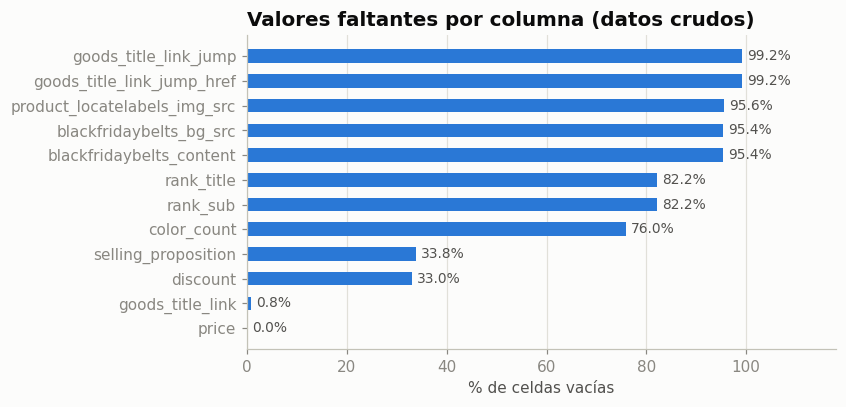

In [ ]:
# % de celdas vacías por columna (isna() marca vacíos; mean() da la proporción; *100 la pasa a %)
faltantes = (raw.drop(columns="categoria").isna().mean() * 100).sort_values(ascending=False)

# Gráfico de barras horizontales: una barra por columna
fig, ax = plt.subplots(figsize=(7.8, 3.8))
ax.barh(faltantes.index[::-1], faltantes.values[::-1], color=AZUL, height=0.55)   # [::-1] invierte el orden: la mayor queda arriba
for y, v in enumerate(faltantes.values[::-1]):       # escribimos el % al final de cada barra
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, 118); ax.set_xlabel("% de celdas vacías")   # 118 deja lugar para los rótulos
ax.set_title("Valores faltantes por columna (datos crudos)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Cómo interpretar el resultado: cuanto más larga es la barra, mayor es la cantidad de celdas vacías en esa columna.

En `goods_title_link` hay apenas un 1% de valores vacíos, mientras que en `goods_title_link_jump` falta casi el 99%. Esto no significa que falten los títulos, sino que están repartidos entre ambas columnas. Al unirlas, podemos recuperar los títulos de todos los productos.

Por otro lado, `goods_title_link_jump_href`, que contiene los enlaces a los productos, está casi completamente vacía, así que no la vamos a usar.

En las columnas `discount`, `selling_proposition` y las relacionadas con el `ranking`, que haya celdas vacías no significa necesariamente que haya un error. Puede indicar que el producto no tiene descuento, no muestra ventas recientes o no aparece en un ranking. Por eso, tenemos que tener en cuenta qué significa cada valor vacío al preparar los datos en el paso 2.5.

## 2. Preprocesamiento
En esta parte preparamos los datos para poder trabajar con ellos. Para eso, seguimos ocho pasos: unimos las columnas que contienen los títulos, convertimos los datos al tipo correspondiente, eliminamos duplicados, corregimos inconsistencias, tratamos los valores faltantes, creamos nuevas variables, definimos la variable que queremos predecir y, por último, preparamos una muestra para aplicar los modelos.

Esto es necesario porque los algoritmos necesitan datos consistentes para funcionar correctamente. Si dejamos productos duplicados, valores faltantes o precios imposibles, los resultados pueden verse afectados. Por eso, en cada paso mostramos cómo estaban los datos antes de modificarlos y cómo quedan después, para poder entender y justificar las decisiones que tomamos durante la limpieza.

### 2.1 Unificar columnas y limpiar el texto
En este paso unificamos las dos columnas que contienen el título de los productos en una sola llamada nombre. Si una fila no tiene título en `goods_title_link`, usamos el de `goods_title_link_jump`.

También cambiamos los nombres de las demás columnas por otros más claros en español, como `color_count`, que pasa a llamarse `colores`. Además, eliminamos los enlaces y las etiquetas de Black Friday, ya que casi siempre están vacíos y no aportan información útil para el análisis.

Otra decisión que tomamos es excluir la categoría `swimwear`, porque su archivo no tiene la columna de ventas. Como las ventas son una variable importante para el trabajo, no podríamos diferenciar los productos sin ventas de aquellos para los que simplemente no se informó ese dato.

Por último, limpiamos los títulos, quitando los espacios innecesarios y creando una versión en minúsculas llamada `nombre_norm`.

Esto nos permite trabajar con los títulos de manera más consistente. Por ejemplo, `" Portable Fan "` y `"portable fan"` se reconocen como el mismo texto, lo que facilita la detección de duplicados y la extracción de palabras.

In [ ]:
# =====================================================================
# 2. PREPROCESAMIENTO — 2.1 Unificar columnas y limpiar el texto
# Armamos una tabla nueva "df" solo con las columnas útiles y con nombres en español.
# =====================================================================

def col(nombre):                    # devuelve la columna, o vacía si ese archivo no la trae
    return raw[nombre] if nombre in raw.columns else pd.Series(np.nan, index=raw.index)

df = pd.DataFrame({
    "categoria": raw["categoria"],
    "nombre": col("goods_title_link").fillna(col("goods_title_link_jump")),   # unimos las dos columnas de título
    "precio": col("price"), "descuento": col("discount"), "vendidos": col("selling_proposition"),
    "ranking": col("rank_title"), "subcategoria": col("rank_sub"), "colores": col("color_count"),
})
# Categorías cuyo archivo no trae la columna de ventas: se descartan (no se puede distinguir "sin ventas" de "no informado")
sin_ventas = [d["categoria"].iloc[0] for d in partes if "selling_proposition" not in d.columns]
print("Categorías descartadas por no tener columna de ventas:", sin_ventas)
df = df[~df["categoria"].isin(sin_ventas)].reset_index(drop=True)   # ~ = "no": nos quedamos con las demás

# Limpieza del título: espacios múltiples -> uno solo, y sin espacios en los bordes
df["nombre"] = df["nombre"].str.replace(r"\s+", " ", regex=True).str.strip()
df["nombre_norm"] = df["nombre"].str.lower()        # copia en minúsculas, para comparar títulos (duplicados)
print("Títulos vacíos después de unir:", df["nombre"].isna().sum(), "de", num(len(df)), "(se descartan en 2.5)")
df.head()

Categorías descartadas por no tener columna de ventas: ['swimwear']
Títulos vacíos después de unir: 14 de 78.345 (se descartan en 2.5)


,categoria,nombre,precio,descuento,vendidos,ranking,subcategoria,colores,nombre_norm
0,appliances,"1pc Rechargeable Deep Tissue Muscle Handheld Massage Gun, Suitable...",$2.03,-22%,NaN,#1 Best Sellers,in Give Gifts,NaN,"1pc rechargeable deep tissue muscle handheld massage gun, suitable..."
1,appliances,1pc Portable Hanging Neck Fan,$6.48,-20%,NaN,#4 Best Sellers,in Top rated in Portable Fans,NaN,1pc portable hanging neck fan
2,appliances,1pc Pink Colored Curved Eyelash Curler False Eyelash Auxiliary Mak...,$1.80,NaN,400+ sold recently,NaN,NaN,NaN,1pc pink colored curved eyelash curler false eyelash auxiliary mak...
3,appliances,1 Mini Portable Handheld Fan With 2 Aa Batteries (Batteries Not In...,$0.88,-72%,5.6k+ sold recently,NaN,NaN,NaN,1 mini portable handheld fan with 2 aa batteries (batteries not in...
4,appliances,"Wit Water Flosser,Portable Oral Irrigator With 3 Modes, Nasal Wash...",$12.06,-40%,NaN,#6 Best Sellers,in Oral Irrigators,NaN,"wit water flosser,portable oral irrigator with 3 modes, nasal wash..."


**Cómo leer el resultado:** ahora hay una sola columna `nombre`, con muy pocos vacíos. El resto de las columnas sigue siendo texto: se convierte en el paso siguiente.

### 2.2 Conversión de tipos (texto → número)
Convertimos los textos en números con expresiones regulares:
| Columna | Ejemplo en el archivo | Queda como |
|---|---|---|
| `precio` | `\$1,299.00` | 1299.0 |
| `descuento` | `-22%` | 22 (porcentaje de descuento) |
| `vendidos` | `400+ sold recently` / `5.6k+ sold recently` | 400 / 5600 (cantidad **mínima** vendida) |
| `ranking` | `#4 Best Sellers` | 4 (puesto en el ranking) |
| `subcategoria` | `in Hair Dryers` | `Hair Dryers` |
| `colores` | `3` (texto) | 3 (cantidad de colores) |

**Por qué:** K-Means y la red neuronal solo trabajan con **números**. Lo que no se pueda interpretar queda como faltante en lugar de romper el código. Ojo: `5.6k+` significa "5.600 **o más**", por eso decimos que `vendidos` es un valor mínimo.

In [ ]:
# 2.2 Conversión de tipos: pasamos los textos a números usando expresiones regulares

# Precio: borramos todo lo que no sea dígito o punto ("$", ","). errors="coerce": si no se puede convertir, queda vacío (NaN)
df["precio"] = pd.to_numeric(df["precio"].str.replace(r"[^\d.]", "", regex=True), errors="coerce")   # "$1,299.00" -> 1299.0
# Descuento: extraemos solo el número (sin el "-" ni el "%")
df["descuento"] = pd.to_numeric(df["descuento"].str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")  # "-22%" -> 22

# Vendidos: separamos el número y la "k" (miles) y multiplicamos por 1000 cuando corresponde
v = df["vendidos"].str.extract(r"([\d.]+)\s*(k?)\+", flags=re.I)         # "5.6k+" -> (5.6, "k")
df["vendidos"] = pd.to_numeric(v[0], errors="coerce") * np.where(v[1].str.lower() == "k", 1000, 1)   # 5.6 * 1000 = 5600

# Ranking: nos quedamos con el número que sigue al "#"
df["ranking"] = pd.to_numeric(df["ranking"].str.extract(r"#(\d+)")[0], errors="coerce")             # "#4 Best Sellers" -> 4
# Subcategoría: sacamos el "in " del principio
df["subcategoria"] = df["subcategoria"].str.replace(r"^\s*in\s+", "", regex=True).str.strip()     # "in Hair Dryers" -> "Hair Dryers"
df["colores"] = pd.to_numeric(df["colores"], errors="coerce")                                       # ya es un número escrito como texto

# Control: cuántos valores se convirtieron bien en cada columna y sus estadísticas básicas
print(df[["precio", "descuento", "vendidos", "ranking", "colores"]].notna().sum().to_string())
df[["precio", "descuento", "vendidos", "ranking", "colores"]].describe().round(2)

precio       78343
descuento    51436
vendidos     54364
ranking      14011
colores      17837


,precio,descuento,vendidos,ranking,colores
count,78343.00,51436.00,54364.00,14011.00,17837.00
mean,23.04,23.07,976.52,5.11,8.05
std,3175.95,16.98,1695.85,2.89,5.09
min,0.15,1.00,10.00,1.00,4.00
25%,2.40,9.00,100.00,3.00,5.00
50%,5.60,20.00,300.00,5.00,6.00
75%,11.20,32.00,1000.00,8.00,10.00
max,888888.00,92.00,10000.00,10.00,40.00


Cómo interpretar el resultado: la primera tabla muestra cuántos valores se pudieron convertir correctamente a números en cada columna. En `precio` hay datos para casi todos los productos, mientras que en `descuento`, `vendidos`, `ranking` y `colores` hay menos valores, ya que algunas celdas están vacías desde el origen.

Por otro lado, `describe()` nos permite ver un resumen de los datos, incluyendo los valores mínimos y máximos. En el caso de precio, encontramos una diferencia muy grande entre los valores más bajos y los más altos. Hay precios de unos pocos centavos y otros que llegan a cientos de miles de dólares, por lo que tendremos que revisar los valores sospechosos en el paso 2.4.

También vemos que el mínimo de `vendidos` es 10. Esto se debe a que SHEIN muestra la etiqueta de ventas recientes a partir de esa cantidad, por lo que no significa que los productos con menos ventas estén representados con un cero.

### 2.3 Duplicados
En este paso eliminamos los productos duplicados. Para identificarlos, tenemos en cuenta que tengan el mismo título y el mismo precio. Si encontramos varias copias de un producto, conservamos la que tenga más información disponible, como el descuento, las ventas o el ranking.

Esto es importante porque, si dejamos productos repetidos, pueden influir más de lo debido en los promedios y en el entrenamiento de los modelos. Además, si una copia queda en los datos de entrenamiento y otra en los de prueba, la red neuronal podría dar resultados engañosamente buenos. Como en el paso anterior normalizamos los títulos, también podemos detectar como iguales aquellos que solo se diferencian por las mayúsculas o los espacios de más.

In [ ]:
# 2.3 Duplicados
n0 = len(df)                                    # guardamos la cantidad de filas inicial para comparar al final
print("Filas completamente idénticas       :", df.drop(columns="nombre_norm").duplicated().sum())
print("Repetidas por título + precio       :", df.duplicated(subset=["nombre_norm", "precio"]).sum())
# mismo título en distintas categorías (el mismo producto publicado en más de una sección)
print("Títulos que aparecen en más de una categoría:", num(df.groupby("nombre_norm")["categoria"].nunique().gt(1).sum()))

# Ordenamos para que, entre copias, quede primero la que tiene más datos, y borramos el resto
df["_info"] = df[["descuento", "vendidos", "ranking"]].notna().sum(axis=1)   # columna auxiliar: cuántos de esos 3 datos tiene la fila
df = (df.sort_values("_info", ascending=False, kind="stable")             # 1) las filas con más datos primero
        .drop_duplicates(subset=["nombre_norm", "precio"], keep="first")   # 2) de cada grupo repetido queda la primera
        .drop(columns="_info").sort_index().reset_index(drop=True))        # 3) borramos la auxiliar y volvemos al orden original
print(f"\nFilas antes: {num(n0)} | después: {num(len(df))} | eliminadas: {num(n0 - len(df))} ({(n0-len(df))/n0:.1%})")

Filas completamente idénticas       : 2670
Repetidas por título + precio       : 7917
Títulos que aparecen en más de una categoría: 3.891

Filas antes: 78.345 | después: 70.428 | eliminadas: 7.917 (10.1%)


Cómo interpretar el resultado: las primeras dos líneas muestran cuántos productos están duplicados exactamente y cuántos se repiten al comparar el título y el precio. La segunda cantidad incluye a la primera. Después de eliminar los duplicados, podemos ver cuánto se redujo el total de productos. Si el porcentaje eliminado es bajo, significa que la limpieza no afecta demasiado la cantidad de datos disponibles.

Es importante aclarar que un producto con el mismo título, pero distinto precio, no se elimina, porque puede tratarse de una variante o de un cambio de precio.

También puede pasar que un mismo producto aparezca en varias categorías, como `home and kitchen` y `appliances`. En esos casos, conservamos una sola copia en la categoría que tenga más información disponible. Si ambas tienen la misma cantidad de información, dejamos la que aparece primero por orden alfabético.

### 2.4 Inconsistencias
En este paso revisamos si hay valores que no tienen sentido, como precios iguales o menores que cero, descuentos fuera del rango del 1 al 99%, ventas inferiores a 10 o rankings fuera de los primeros 10 puestos. También comprobamos que los datos del ranking sean coherentes entre sí, porque puede aparecer una subcategoría sin un puesto asignado o al revés.

Cuando encontramos valores imposibles, no intentamos corregirlos inventando un número, sino que los dejamos como faltantes para no introducir información incorrecta.

Con los precios extremos hacemos algo distinto, porque un precio alto no significa necesariamente que esté mal. Por ejemplo, un sillón de masajes de 2.400 dólares o un gazebo de 2.000 pueden ser productos reales. Por eso, revisamos los precios junto con el título para distinguir los casos válidos de los que parecen errores.

Para este trabajo establecemos un límite de 10.000 dólares (`PRECIO_MAX = 10.000`), ya que consideramos que ningún producto real de esta tienda debería superar ese valor. Así, descartamos registros claramente falsos, como el que tiene un precio de 888.888 dólares y un título de prueba. Este límite es una decisión que tomamos para la limpieza de los datos, no una regla propia de SHEIN.

In [ ]:
# 2.4 Inconsistencias: contamos valores que no tienen sentido en cada columna
print("precio <= 0                     :", num((df["precio"] <= 0).sum()))
print("descuento fuera de 1-99         :", num(((df["descuento"] < 1) | (df["descuento"] > 99)).sum()))
print("vendidos menor a 10             :", num((df["vendidos"] < 10).sum()))
print("ranking fuera de 1-10           :", num(((df["ranking"] < 1) | (df["ranking"] > 10)).sum()))
# si un producto tiene ranking debería tener subcategoría, y viceversa
print("ranking sin subcategoría (o al revés):", num((df["ranking"].isna() != df["subcategoria"].isna()).sum()))

# Revisión manual de los precios más altos: ¿son productos reales o errores?
pd.set_option("display.max_colwidth", 90)       # mostramos títulos más largos para poder leerlos
display(df.nlargest(8, "precio")[["categoria", "nombre", "precio"]])   # los 8 productos más caros

PRECIO_MAX = 10_000          # decisión nuestra: ningún producto real de la tienda supera este precio
print("Precios mayores a PRECIO_MAX:", int((df["precio"] > PRECIO_MAX).sum()))
df.loc[df["precio"] > PRECIO_MAX, "precio"] = np.nan   # el registro de prueba ($888.888) queda sin precio

# Los valores imposibles se marcan como faltantes (no se "arreglan" a mano)
df.loc[df["precio"] <= 0, "precio"] = np.nan
df.loc[(df["descuento"] < 1) | (df["descuento"] > 99), "descuento"] = np.nan
df.loc[df["vendidos"] < 10, "vendidos"] = np.nan
df.loc[(df["ranking"] < 1) | (df["ranking"] > 10), "ranking"] = np.nan

# Y los más bajos, para confirmar que no son errores
display(df.nsmallest(4, "precio")[["categoria", "nombre", "precio"]])
pd.set_option("display.max_colwidth", 70)       # volvemos al ancho normal

precio <= 0                     : 0
descuento fuera de 1-99         : 0
vendidos menor a 10             : 0
ranking fuera de 1-10           : 0
ranking sin subcategoría (o al revés): 0


,categoria,nombre,precio
30053,home textile,This Is A Very Goods Product Name A A A A !!! 00000 Aaaaabbbbbcccccsssss,888888.00
3253,appliances,"BOSSCARE Full Body Zero Gravity 4D Massage Chair, 2024 APP & AI Control Massage Reclin...",2399.99
43259,office and school supplies,Brunello Cucinelli Bags.. Dove Grey,2305.46
2737,appliances,"VEVOR Commercial Ice Cream Machine, 20-25L/H Yield, 2400W 1-Flavor Hard Serve Ice Crea...",2254.99
58739,tools and home improvement,"12X20 FT Outdoor Galvanised Steel Hardtop Gazebo, Heavy Duty Double Roof Outdoor Gazeb...",1998.99
58885,tools and home improvement,Manhattan Comfort Fifth Avenue Faux Leather Barstool (Set Of 3),1568.71
3714,appliances,"BOSSCARE 3D Full Body SL Track Massage Chair, APP Control, Body Scanning, Zero Gravity...",1499.99
1404,appliances,"VEVOR Slushy Machine, 30L Slushie Machine For Home, 1250W Commercial Slushy Machine, S...",1430.99


Precios mayores a PRECIO_MAX: 1


,categoria,nombre,precio
15949,beauty and health,6 Sheets (288pcs) French Nail Art Stickers With Wavy Circle Patterns And Modeling Temp...,0.15
17151,beauty and health,Black Friday 1pack Star Design Nail Art Sequin DIY Nail Charms Nail Gems Nail Supplies,0.15
17504,beauty and health,Black Friday 10ml Shiny Sugar Nail Glitter Powder For Manicure Y2K Flock Powder Nail A...,0.18
17517,beauty and health,Black Friday 10ml Shiny Sugar Nail Glitter Powder For Manicure Flock Powder Nail Art D...,0.18


Los primeros resultados muestran cuántos registros tenían cada uno de los problemas que buscamos. Si la cantidad es baja o directamente es cero, significa que la mayoría de los datos no presenta esas inconsistencias.

En la tabla de precios más altos podemos ver el precio junto con el título de cada producto. El primero, de 888.888 dólares, tiene un título que dice "This Is A Very Goods Product Name...", por lo que identificamos que es un registro de prueba falso y lo eliminamos usando el límite `PRECIO_MAX`. En cambio, los siguientes productos, como sillones de masaje, gazebos y una PC gamer, tienen precios elevados, pero corresponden a artículos reales, así que los conservamos.

La segunda tabla muestra los productos más baratos para comprobar que tampoco se trate de errores. Esta revisión manual nos permite distinguir los valores que realmente están mal de aquellos que simplemente se encuentran en los extremos del rango de precios.

### 2.5 Valores faltantes
En este paso tratamos los datos faltantes según la información que necesitamos para el análisis.

Primero, eliminamos los productos que no tienen precio o título, porque son datos esenciales para el trabajo. Sin el precio no podemos determinar si un producto es barato, medio o caro, y sin el título perdemos información que después vamos a utilizar.

Para las demás columnas, asignamos valores según lo que significa que estén vacías:
- `descuento`: si está vacío, asignamos 0 y creamos la marca `tiene_descuento` para identificar los productos que tienen un descuento.
- `vendidos`: si no hay información, asignamos 0 y creamos `tiene_vendidos` para distinguir los productos que tienen un dato de ventas de los que no.
- `ranking`: si está vacío, asignamos 0 a `es_bestseller`, indicando que el producto no aparece en el ranking.
- `subcategoria`: cuando falta, usamos `Sin ranking`. Esta columna se utiliza solamente en algunos gráficos.
- `colores`: si no se informa la cantidad de colores disponibles, asignamos 0.
Tomamos estas decisiones porque un dato vacío no siempre significa lo mismo. Por ejemplo, un producto sin descuento no es igual a uno cuyo descuento desconocemos. En lugar de completar los valores con una mediana u otro número que podría no representar la realidad, usamos valores que tengan un significado dentro del análisis.

De todos modos, estas asignaciones son decisiones nuestras y tenemos que tenerlas en cuenta al explicar las limitaciones del trabajo. En particular, en las categorías `automotive` y `baby and maternity` no existe la columna de ranking, por lo que `es_bestseller = 0` significa que no tenemos ese dato, y no necesariamente que el producto no sea un Best Seller.

In [ ]:
# 2.5 Valores faltantes
n0 = len(df)
# Sin precio o sin título el producto no sirve para el análisis: esas filas se eliminan
df = df.dropna(subset=["precio", "nombre"]).reset_index(drop=True)
print(f"Filas antes: {num(n0)} | después: {num(len(df))} ({len(df)/n0:.1%} conservado)")

# Para estas columnas, el vacío significa "no tiene": guardamos esa información en una marca 0/1
df["tiene_descuento"] = df["descuento"].notna().astype(int)   # 1 = tiene descuento, 0 = no
df["tiene_vendidos"] = df["vendidos"].notna().astype(int)     # 1 = muestra ventas, 0 = no
df["es_bestseller"] = df["ranking"].notna().astype(int)       # 1 = está en el ranking Best Sellers, 0 = no
# Después de guardar la marca, completamos (imputamos) los vacíos con 0 o con un texto fijo
df["descuento"] = df["descuento"].fillna(0)
df["vendidos"] = df["vendidos"].fillna(0)
df["colores"] = df["colores"].fillna(0)
df["subcategoria"] = df["subcategoria"].fillna("Sin ranking")

# Control: qué % de productos tiene cada característica (el promedio de una columna 0/1 es un porcentaje)
print("\nProductos con descuento      :", f"{df['tiene_descuento'].mean():.1%}")
print("Productos con ventas visibles:", f"{df['tiene_vendidos'].mean():.1%}")
print("Productos Best Seller        :", f"{df['es_bestseller'].mean():.1%}")
print("Productos con ranking Y ventas visibles a la vez:", int(((df["es_bestseller"] == 1) & (df["tiene_vendidos"] == 1)).sum()))
print("Faltantes restantes (precio, descuento, vendidos):", int(df[["precio", "descuento", "vendidos"]].isna().sum().sum()))   # debería dar 0

Filas antes: 70.428 | después: 70.416 (100.0% conservado)

Productos con descuento      : 65.6%
Productos con ventas visibles: 69.5%
Productos Best Seller        : 17.8%
Productos con ranking Y ventas visibles a la vez: 0
Faltantes restantes (precio, descuento, vendidos): 0


Después de eliminar los productos sin precio o título, revisamos cuántos registros quedaron y qué porcentaje tiene información sobre descuentos, ventas y rankings. Estos datos nos sirven para entender mejor las características de los productos. Por ejemplo, podemos ver que la mayoría no aparece como Best Seller y que menos de la mitad muestra información sobre ventas recientes.

También comprobamos si hay productos que tengan al mismo tiempo un ranking y una etiqueta de ventas recientes. Si el resultado es cero, significa que en los datos de esta tienda ambas etiquetas no aparecen juntas: un producto puede figurar como Best Seller o mostrar ventas recientes, pero no las dos cosas a la vez. Esto es importante para tener en cuenta al analizar los resultados de los modelos.

Por último, verificamos que no queden valores numéricos faltantes, ya que los reemplazamos por 0 durante este paso.

### 2.6 Variables nuevas (*feature engineering*)
En este paso creamos nuevas variables a partir de los datos que ya tenemos, principalmente del título y de las columnas que limpiamos anteriormente.
- `n_palabras` y `largo_nombre`: indican cuántas palabras y caracteres tiene el título de cada producto.
- `es_1pc`: vale 1 si el título empieza con "1pc", "1 pc" o "1 ". Esto nos ayuda a identificar publicaciones que parecen corresponder a una sola unidad, algo común en accesorios pequeños.
- `log_precio` y `log_vendidos`: son versiones de los precios y las ventas transformadas mediante logaritmos.
- `precio_rel`: compara el precio de cada producto con la mediana de su categoría. Por ejemplo, un valor de 1 significa que cuesta lo mismo que el precio típico de su categoría, mientras que un valor de 2 significa que cuesta el doble.
- `log_precio_rel`: es la versión logarítmica de esa comparación.
Creamos estas variables porque los precios y las ventas tienen algunos valores mucho más grandes que el resto, lo que puede dificultar el análisis. Aplicar logaritmos ayuda a reducir esas diferencias. Además, las variables relacionadas con el título nos permiten representar algunas de sus características mediante números, que son los que utilizan los algoritmos para trabajar.

In [ ]:
# 2.6 Variables nuevas (feature engineering), calculadas a partir de las que ya tenemos
df["n_palabras"] = df["nombre"].str.split().str.len()      # cantidad de palabras del título
df["largo_nombre"] = df["nombre"].str.len()                # cantidad de caracteres del título
# 1 si el título empieza con "1pc", "1 pcs", "1 piece" o "1 " (se vende una sola unidad), 0 si no
df["es_1pc"] = df["nombre"].str.match(r"^\s*1\s?(?:pcs?|piece)?[\s,]", case=False).astype(int)
df["log_precio"] = np.log1p(df["precio"])                  # log(1 + precio): comprime precios muy dispersos
df["log_vendidos"] = np.log1p(df["vendidos"])              # lo mismo con las ventas (log1p evita el error de log(0))
# Precio relativo: precio del producto dividido el precio mediano de su categoría (1 = precio típico)
df["precio_rel"] = df["precio"] / df.groupby("categoria")["precio"].transform("median")
df["log_precio_rel"] = np.log(df["precio_rel"])         # 0 = precio típico de su categoría; +1 = unas 2,7 veces más

print("Productos:", num(len(df)), "| categorías:", df["categoria"].nunique())
df[["precio", "precio_rel", "descuento", "vendidos", "colores", "n_palabras", "largo_nombre", "es_1pc"]].describe().round(2)

Productos: 70.416 | categorías: 20


,precio,precio_rel,descuento,vendidos,colores,n_palabras,largo_nombre,es_1pc
count,70416.00,70416.00,70416.00,70416.00,70416.00,70416.00,70416.00,70416.00
mean,11.72,2.19,15.02,674.64,1.84,17.03,114.38,0.22
std,38.12,8.87,17.43,1480.91,4.16,10.39,73.47,0.41
min,0.15,0.03,0.00,0.00,0.00,2.00,9.00,0.00
25%,2.45,0.65,0.00,0.00,0.00,10.00,65.00,0.00
50%,5.69,1.00,8.00,100.00,0.00,15.00,99.00,0.00
75%,11.24,1.64,24.00,600.00,0.00,21.00,145.00,0.00
max,2399.99,1002.37,92.00,10000.00,40.00,197.00,997.00,1.00


La tabla muestra los valores mínimos, máximos, promedios y medianas de cada variable. En el caso de `precio`, vemos que la mediana (50%) está bastante por debajo del promedio (mean) y que el valor máximo es muy alto. Esto indica que hay unos pocos productos muy caros que elevan el promedio, aunque la mayoría tiene precios mucho más bajos. Por eso usamos la mediana para comparar precios y aplicamos logaritmos para reducir el efecto de esas diferencias.

En `es_1pc`, el promedio representa la proporción de productos cuyo título indica que se trata de una sola unidad. Por ejemplo, si el promedio fuera 0.3, significaría que el 30% de los productos cumple esa condición.

### 2.7 Variable objetivo: nivel de precio
Clasificamos cada producto como Barato, Medio o Caro, según su precio. Para hacerlo, dividimos los productos en tres grupos usando terciles: el tercio más barato, el del medio y el más caro. La división se hace dentro de cada categoría, comparando ropa con ropa y herramientas con herramientas. Las categorías con menos de 100 productos se agruparían en `otras`, aunque en este caso ninguna cumple esa condición.
Lo hacemos asi ya que:
- Una red neuronal de clasificación predice categorías, no precios exactos.
- Usar terciles permite que los tres grupos tengan una cantidad similar de productos.
- Los precios varían mucho entre categorías. Por ejemplo, la mediana de jewelry es de unos 2 dólares, mientras que la de shoes ronda los 13. Si usáramos un único criterio de precio para todos, los productos de categorías más caras tendrían ventaja para quedar en el grupo «Caro». Al comparar dentro de cada categoría, buscamos responder una pregunta más útil: ¿qué distingue a un producto caro de uno barato dentro de su propio tipo?
- Estas clases las definimos para el análisis; no son categorías oficiales de SHEIN.

In [ ]:
# 2.7 Variable objetivo: nivel de precio (Barato / Medio / Caro)
MIN_CAT = 100          # categorías con menos productos se agrupan en "otras"
conteo = df["categoria"].value_counts()                   # cuántos productos tiene cada categoría
# where: deja la categoría si tiene 100 o más productos; si no, la reemplaza por "otras"
df["categoria"] = df["categoria"].where(df["categoria"].map(conteo) >= MIN_CAT, "otras")

# Posición del precio dentro de su categoría (0 a 1) y corte en terciles
pos = df.groupby("categoria")["precio"].rank(pct=True)    # ej.: 0.25 = más caro que el 25% de su categoría
# pd.cut divide en 3 tramos iguales: primer tercio = Barato, segundo = Medio, tercero = Caro
df["nivel_precio"] = pd.cut(pos, bins=[0, 1/3, 2/3, 1.0], labels=["Barato", "Medio", "Caro"], include_lowest=True)

# Control: cantidad de productos y rango de precio relativo de cada nivel
cortes = df.groupby("nivel_precio", observed=True)["precio_rel"].agg(["count", "min", "median", "max"])
display(cortes.round(2))
print("Dataset limpio:", df.shape)

,count,min,median,max
nivel_precio,,,,
Barato,23457,0.03,0.53,0.84
Medio,23444,0.54,1.00,1.92
Caro,23515,1.20,2.12,1002.37


Dataset limpio: (70416, 20)


Cómo leer el resultado: la tabla muestra cuántos productos hay en cada nivel y el rango de precios en relación con su categoría, incluyendo el mínimo, la mediana y el máximo. Un precio relativo de 1 equivale al precio típico de esa categoría.

Los tres grupos deberían tener una cantidad similar de productos, aunque puede haber pequeñas diferencias porque muchos productos tienen exactamente el mismo precio y los cortes pueden coincidir con esos valores repetidos.

Como la clasificación se hace dentro de cada categoría, los precios de los distintos grupos pueden variar mucho. Por ejemplo, un producto «Caro» de jewelry puede costar menos que uno «Barato» de appliances. Por eso mostramos también `precio_rel`, que permite comparar el precio de cada producto con el habitual en su propia categoría.

### 2.8 Muestra para modelar
Tomamos una muestra aleatoria de 30.000 productos de los más de 65.000 que quedaron después de la limpieza. Usamos esa muestra para entrenar K-Means y la red neuronal, porque trabajar con todos los datos haría que el entrenamiento y el cálculo de la silueta tardaran demasiado en Colab.

Al elegir los productos al azar, buscamos conservar una distribución parecida a la del conjunto completo y reducir el tiempo de procesamiento. Además, usamos una semilla fija para que la muestra sea la misma cada vez que ejecutamos el código.

Los gráficos de la sección 3 sí se generan con todos los productos limpios, no solamente con la muestra.

In [ ]:
# 2.8 Muestra para modelar: tomamos 30.000 productos al azar (entrenar con todos tardaría mucho más)
N_MODELO = 30_000
# min(...) evita error si el dataset tuviera menos de 30.000 filas; random_state=SEED: siempre la misma muestra
dfm = df.sample(n=min(N_MODELO, len(df)), random_state=SEED).reset_index(drop=True)
print("Productos limpios:", num(len(df)), "| muestra para modelar:", num(len(dfm)))
# Control: la muestra debe mantener un tercio de productos en cada nivel
print("\nProporción de cada nivel (muestra):")
print(dfm["nivel_precio"].value_counts(normalize=True).round(3).to_string())

Productos limpios: 70.416 | muestra para modelar: 30.000

Proporción de cada nivel (muestra):
nivel_precio
Medio     0.337
Caro      0.334
Barato    0.329


**Cómo leer el resultado:** las proporciones de la muestra deben ser casi iguales a las del total (un tercio por nivel): eso confirma que **es representativa**.

## 3. Exploración visual (paso a paso)
En esta sección analizamos los datos con siete gráficos. Empezamos por la distribución de los precios y los tipos de productos, después vemos los descuentos, las diferencias entre productos baratos y caros, las ventas, las correlaciones entre variables y, por último, las palabras que aparecen en los títulos.

Esta parte sirve para conocer mejor los datos antes de aplicar los algoritmos. Al observarlos, podemos detectar posibles problemas, encontrar patrones y plantear hipótesis que después nos ayuden a interpretar los resultados de los modelos. Cada gráfico nos permite analizar un aspecto distinto del dataset.

### Paso 1 — ¿Cómo se distribuyen los precios?
Hacemos un histograma para ver cómo se distribuyen los precios de los productos y marcamos la mediana con una línea. El eje horizontal usa una escala logarítmica porque hay precios que van desde unos centavos hasta miles de dólares.

Si usáramos una escala normal, la mayoría de los productos quedaría concentrada en la parte izquierda del gráfico y sería difícil distinguir la distribución. En cambio, con la escala logarítmica, cada salto representa multiplicar el valor por 10 (1, 10, 100, 1.000), lo que permite apreciar mejor los precios de todo el conjunto.

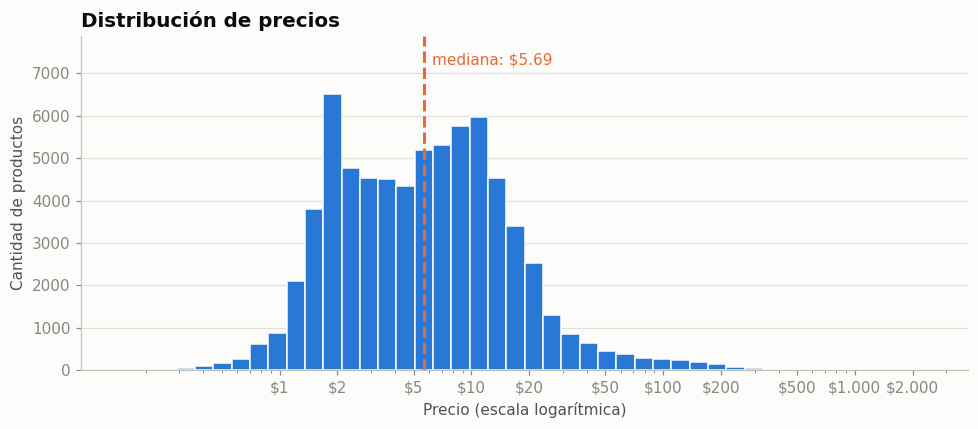

In [ ]:
# =====================================================================
# 3. EXPLORACIÓN VISUAL — Paso 1: histograma de precios
# =====================================================================
fig, ax = plt.subplots(figsize=(9, 4))
# 45 intervalos espaciados en escala logarítmica (del precio mínimo al máximo), para que las barras se vean parejas
bins = np.logspace(np.log10(df["precio"].min()), np.log10(df["precio"].max()), 45)
ax.hist(df["precio"], bins=bins, color=AZUL, edgecolor="#fcfcfb")
ax.set_xscale("log")                                                    # eje X logarítmico: cada salto multiplica el precio
ax.set_xticks([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]); ax.xaxis.set_major_formatter(precio_fmt)   # marcas del eje en $
ax.xaxis.set_minor_formatter(NullFormatter())                          # ocultamos las marcas secundarias

# Línea vertical con la mediana del precio
med = df["precio"].median()
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)                      # espacio arriba para el rótulo
ax.axvline(med, color=NARANJA, linestyle="--")
ax.text(med * 1.1, ax.get_ylim()[1] * 0.95, f"mediana: {esc('$')}{med:.2f}", color=NARANJA, fontsize=10, va="top")
if df["categoria"].nunique() == 1:          # con una sola categoría marcamos dónde están los cortes de Barato / Medio / Caro
    for c in cortes["max"].iloc[:2]:
        ax.axvline(c, color=GRIS, linestyle=":")
ax.set_xlabel("Precio (escala logarítmica)"); ax.set_ylabel("Cantidad de productos")
ax.set_title("Distribución de precios")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Cada barra representa un rango de precios y su altura indica cuántos productos tienen un precio dentro de ese rango.

La línea naranja marca la mediana: el 50 % de los productos cuesta menos y el otro 50 % cuesta más. Si aparecen líneas grises punteadas, señalan los límites que usamos para separar los grupos Barato, Medio y Caro.

Lo importante es observar dónde se concentra la mayoría de los productos y si hay una cola larga hacia la derecha. Esa cola representa unos pocos productos con precios mucho más altos que el resto, que pueden elevar el promedio. Por eso, en este caso, la mediana resulta más representativa del precio habitual.

### Paso 2 — ¿Cuánto cuestan los distintos tipos de producto?
Comparamos los precios de las distintas categorías de la tienda mediante diagramas de caja (boxplots). Mostramos hasta 20 categorías, ordenadas de menor a mayor según su mediana. Si hubiera una sola categoría, usaríamos las subcategorías del ranking de Best Sellers (`rank_sub`).

Esto nos permite ver cómo cambian los precios según el tipo de producto. El gráfico muestra tanto el precio típico de cada categoría como las diferencias entre sus productos, ya que dentro de una misma categoría puede haber artículos mucho más caros o baratos que otros.

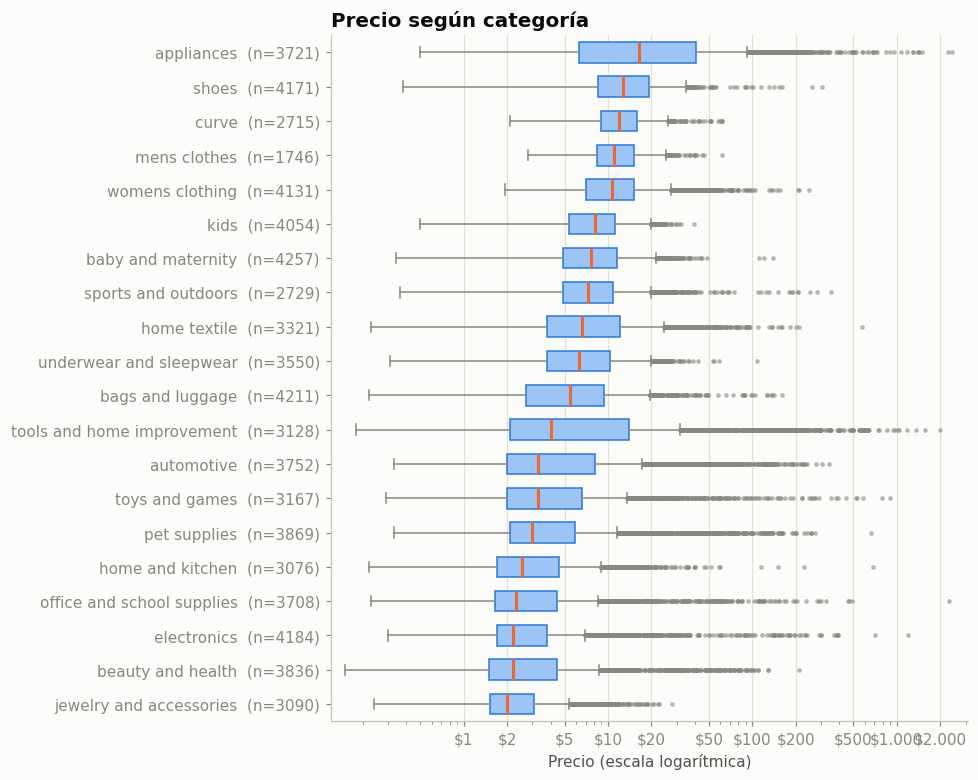

In [ ]:
# Paso 2: boxplot del precio por categoría
# Si hay 3 o más categorías agrupamos por categoría; si no, por subcategoría del ranking
grupo = "categoria" if df["categoria"].nunique() >= 3 else "subcategoria"
sub = df[df[grupo] != "Sin ranking"]                          # sacamos los productos sin subcategoría
top = sub[grupo].value_counts().nlargest(20).index            # nos quedamos con los 20 grupos con más productos
# Ordenamos los grupos de menor a mayor precio mediano (así el gráfico queda escalonado)
orden = sub[sub[grupo].isin(top)].groupby(grupo)["precio"].median().sort_values().index
datos = [sub.loc[sub[grupo] == g, "precio"] for g in orden]   # lista de precios de cada grupo, en ese orden

fig, ax = plt.subplots(figsize=(9, 7.2 if grupo == "categoria" else 5.2))
# boxplot horizontal: caja = 50% central, línea naranja = mediana, puntos grises = valores extremos
bp = ax.boxplot(datos, vert=False, patch_artist=True, widths=0.6, showfliers=True,
                flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor="none", alpha=0.6),
                medianprops=dict(color=NARANJA, linewidth=2), whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS))
for caja in bp["boxes"]:                                       # pintamos cada caja de azul claro
    caja.set(facecolor="#9cc4f4", edgecolor=AZUL)
ax.set_yticklabels([f"{g}  (n={len(d)})" for g, d in zip(orden, datos)])   # rótulo: nombre del grupo + cantidad de productos
ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]); ax.xaxis.set_major_formatter(precio_fmt)
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlim(sub[sub[grupo].isin(top)]["precio"].min() * 0.8, sub[sub[grupo].isin(top)]["precio"].max() * 1.3)   # margen a los costados
ax.set_xlabel("Precio (escala logarítmica)")
ax.set_title("Precio según " + ("categoría" if grupo == "categoria" else "subcategoría del ranking Best Sellers"))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

En cada fila, la caja representa el 50 % central de los productos, la línea naranja marca la mediana y los bigotes muestran el rango habitual de precios. Los puntos grises señalan productos con precios fuera de lo común.

Las categorías permiten comparar cuánto cuestan los distintos tipos de productos. Por ejemplo, podemos ver si la joyería y los accesorios suelen ser más baratos que el calzado o la ropa de hombre. También se puede observar cuánto varían los precios dentro de cada categoría: una caja ancha indica mayor diferencia entre los precios, mientras que una angosta indica que están más concentrados.

La columna `n` muestra cuántos productos hay en cada categoría. Estas diferencias entre las medianas explican por qué más adelante clasificamos los productos como Barato, Medio o Caro dentro de su propia categoría, en lugar de usar un único precio para todos.

### Paso 3 — ¿Cuántos productos tienen descuento y de qué tamaño?
Mostramos un gráfico de barras con el porcentaje de productos en cada tramo de descuento: sin descuento, del 1 al 20 %, del 21 al 40 %, del 41 al 60 % y más del 60 %.

Esto nos permite ver qué tan comunes son los descuentos y cuáles son los más frecuentes. Como el descuento es una de las pocas variables que tenemos sobre la estrategia comercial, conocer su distribución nos ayuda a entender mejor los datos antes de utilizarla en los modelos.

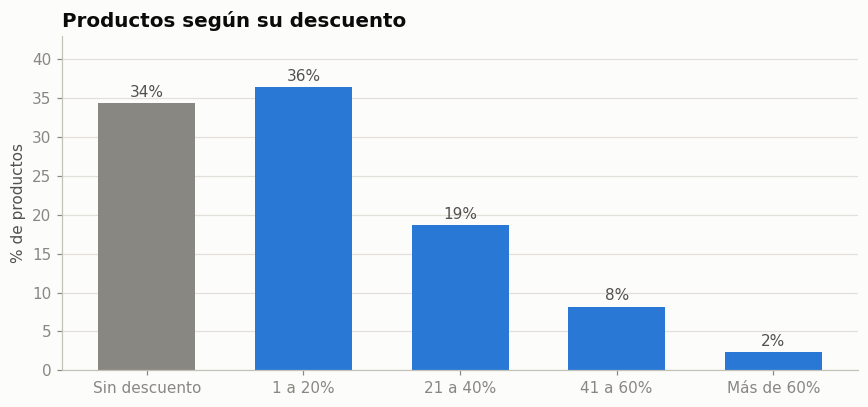

Descuento mediano entre los productos que tienen descuento: 20%


In [ ]:
# Paso 3: % de productos según el tamaño del descuento
# Dividimos el descuento en tramos (el primer tramo, de -0.1 a 0, captura a los que tienen descuento = 0)
tramos = pd.cut(df["descuento"], bins=[-0.1, 0, 20, 40, 60, 100],
                labels=["Sin descuento", "1 a 20%", "21 a 40%", "41 a 60%", "Más de 60%"])
pct = tramos.value_counts(normalize=True).sort_index() * 100   # % de productos en cada tramo

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(pct.index.astype(str), pct.values, color=[GRIS] + [AZUL] * 4, width=0.62)   # "Sin descuento" en gris, el resto en azul
for i, v in enumerate(pct.values):                             # escribimos el % arriba de cada barra
    ax.text(i, v + 0.8, f"{v:.0f}%", ha="center", fontsize=10, color="#52514e")
ax.set_ylim(0, pct.max() * 1.18); ax.set_ylabel("% de productos")
ax.set_title("Productos según su descuento")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"Descuento mediano entre los productos que tienen descuento: {df.loc[df['tiene_descuento'] == 1, 'descuento'].median():.0f}%")

**Cómo leer el resultado:** la barra gris es el % de productos **sin descuento** y las azules, cómo se reparten los que sí tienen. Mirá si el descuento es **la excepción o lo normal** en esta tienda y qué tramos son los más comunes. La línea impresa abajo da el descuento típico entre los que tienen uno.

### Paso 4 — ¿En qué se diferencian los productos baratos de los caros?
Comparamos los productos Baratos, Medios y Caros a partir de cuatro indicadores: qué porcentaje tiene descuento, cuál es el descuento mediano entre los productos que tienen uno, qué porcentaje muestra ventas y cuántos aparecen como Best Sellers.

Esta comparación es central para el trabajo, porque nos permite ver si existen diferencias entre los niveles de precio. Si estos indicadores muestran patrones distintos, podrían ayudar a la red neuronal a predecir si un producto es Barato, Medio o Caro sin utilizar directamente su precio.

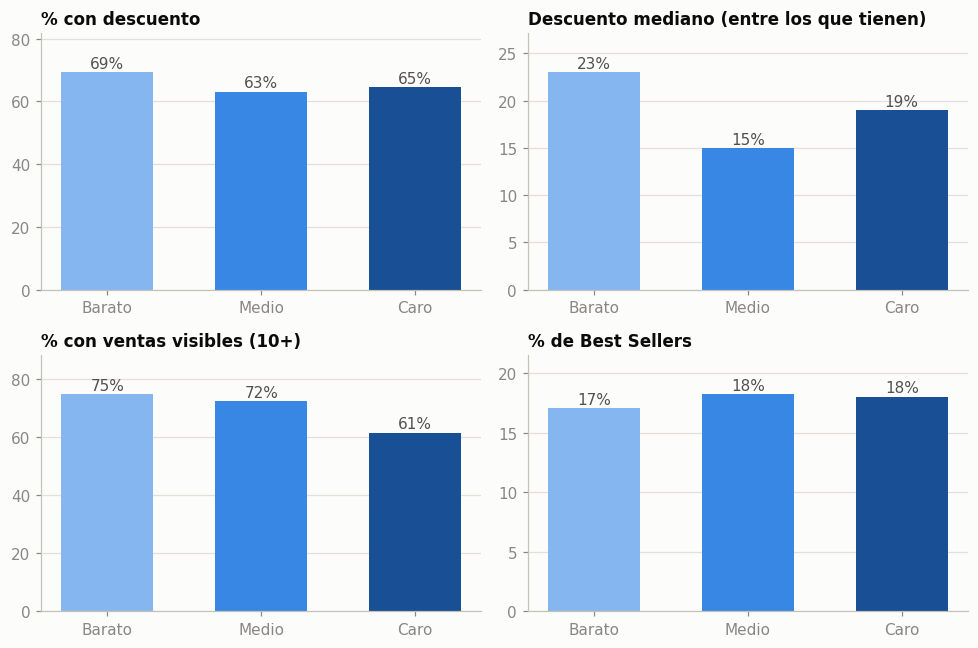

In [ ]:
# Paso 4: comparamos Barato / Medio / Caro en 4 indicadores (un mini-gráfico por indicador)
niveles = ["Barato", "Medio", "Caro"]
m = df.groupby("nivel_precio", observed=True)                 # agrupamos los productos por nivel de precio
# Cada indicador: (título del gráfico, valor por nivel, formato del número)
# reindex(niveles) asegura que siempre salgan en el orden Barato, Medio, Caro
metricas = [
    ("% con descuento", m["tiene_descuento"].mean().reindex(niveles) * 100, "{:.0f}%"),
    ("Descuento mediano (entre los que tienen)", df[df["tiene_descuento"] == 1].groupby("nivel_precio", observed=True)["descuento"].median().reindex(niveles), "{:.0f}%"),
    ("% con ventas visibles (10+)", m["tiene_vendidos"].mean().reindex(niveles) * 100, "{:.0f}%"),
    ("% de Best Sellers", m["es_bestseller"].mean().reindex(niveles) * 100, "{:.0f}%"),
]
fig, axs = plt.subplots(2, 2, figsize=(9, 6))                 # grilla de 2x2 gráficos
for ax, (titulo, serie, f) in zip(axs.ravel(), metricas):     # un indicador en cada casillero
    ax.bar(niveles, serie.values, color=[NIVEL_COL[n] for n in niveles], width=0.6)
    for i, v in enumerate(serie.values):                      # valor escrito arriba de cada barra
        ax.text(i, v + serie.max() * 0.02, f.format(v), ha="center", fontsize=10, color="#52514e")
    ax.set_ylim(0, serie.max() * 1.18); ax.set_title(titulo, fontsize=11); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Cada panel muestra cómo cambia uno de los cuatro indicadores entre los productos Baratos, Medios y Caros. Los colores van del azul más claro al más oscuro para distinguir los tres niveles.

Si las barras cambian claramente de un nivel a otro, significa que ese indicador podría servir para diferenciarlos. Si las barras son parecidas, probablemente aporte menos información para la clasificación.

También podemos interpretar qué muestran los datos sobre la parte comercial: por ejemplo, en qué nivel aparecen más etiquetas de ventas recientes, dónde hay más Best Sellers y qué productos tienen más descuentos.

Hay que tener en cuenta que estas diferencias muestran asociaciones, no causas. Por ejemplo, si los productos baratos muestran más ventas, eso no significa necesariamente que bajar el precio haga que un producto venda más.

### Paso 5 — ¿Los productos que más venden son más baratos para su categoría?
Hacemos un gráfico de dispersión para comparar el precio relativo de cada producto con sus ventas. El precio relativo indica cuánto cuesta en comparación con el precio típico de su categoría: un valor de 1 significa que está en el precio habitual. Ambos ejes usan escala logarítmica para facilitar la comparación entre valores muy distintos.

Solo incluimos los productos que muestran una etiqueta de ventas, es decir, aquellos con 10 ventas o más. Los demás figuran con 0 porque asumimos que no tienen ventas visibles, pero eso no significa que realmente no hayan vendido nada. Incluirlos podría distorsionar la relación entre precio y ventas, por eso los dejamos afuera de este gráfico.

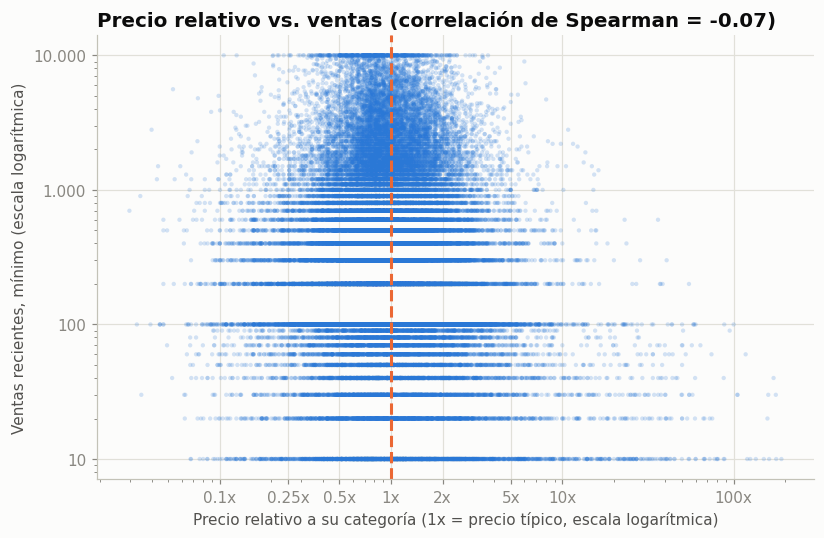

Productos con ventas visibles: 48.963 de 70.416


In [ ]:
# Paso 5: ¿los productos que más venden son más baratos para su categoría?
v = df[df["tiene_vendidos"] == 1]                              # solo productos que muestran ventas
rho = v[["precio_rel", "vendidos"]].corr(method="spearman").iloc[0, 1]      # Spearman: compara posiciones, no valores exactos

# Gráfico de dispersión: cada punto es un producto (X = precio relativo, Y = ventas)
fig, ax = plt.subplots(figsize=(7.6, 5))
ax.scatter(v["precio_rel"], v["vendidos"], s=8, color=AZUL, alpha=0.2, edgecolor="none")   # alpha=0.2: puntos transparentes para ver dónde se acumulan
ax.set_xscale("log"); ax.set_yscale("log")                    # ambos ejes en escala logarítmica
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 5, 10, 100]); ax.xaxis.set_major_formatter(FuncFormatter(lambda v_, _: f"{v_:g}x")); ax.xaxis.set_minor_formatter(NullFormatter())
ax.axvline(1, color=NARANJA, linestyle="--")                       # precio típico de su categoría
ax.set_yticks([10, 100, 1000, 10000]); ax.yaxis.set_major_formatter(miles); ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Precio relativo a su categoría (1x = precio típico, escala logarítmica)"); ax.set_ylabel("Ventas recientes, mínimo (escala logarítmica)")
ax.set_title(f"Precio relativo vs. ventas (correlación de Spearman = {rho:.2f})")
plt.tight_layout(); plt.show()
print(f"Productos con ventas visibles: {num(len(v))} de {num(len(df))}")

Cada punto representa un producto. En el título del gráfico aparece la correlación de Spearman, que indica cómo se relacionan el precio y las ventas. Si es negativa, los productos más caros tienden a vender menos; si está cerca de cero, hay poca relación entre ambas variables.
- La línea naranja marca el precio típico de la categoría. Mirá si la nube de puntos **baja de izquierda a derecha**: es lo que esperaríamos (lo barato para su categoría vende más unidades).
- Fijate que las ventas están **en tramos** (10, 20, 30, 100...), por eso los puntos forman filas horizontales: es una limitación del dato, no un error del gráfico.
- Correlación débil o moderada = hay tendencia pero con **mucha dispersión**: el precio solo no explica las ventas.

### Paso 6 — ¿Qué variables se relacionan entre sí? (matriz de correlación)
Calculamos la correlación de Spearman entre las variables numéricas y mostramos los resultados en un mapa de calor. Así podemos ver en un solo gráfico qué variables tienden a aumentar o disminuir juntas y qué tan fuerte es esa relación.

También nos sirve para detectar variables que aportan información muy parecida. Si dos variables están muy relacionadas, podrían ser redundantes, algo que conviene tener en cuenta antes de utilizarlas en los modelos.

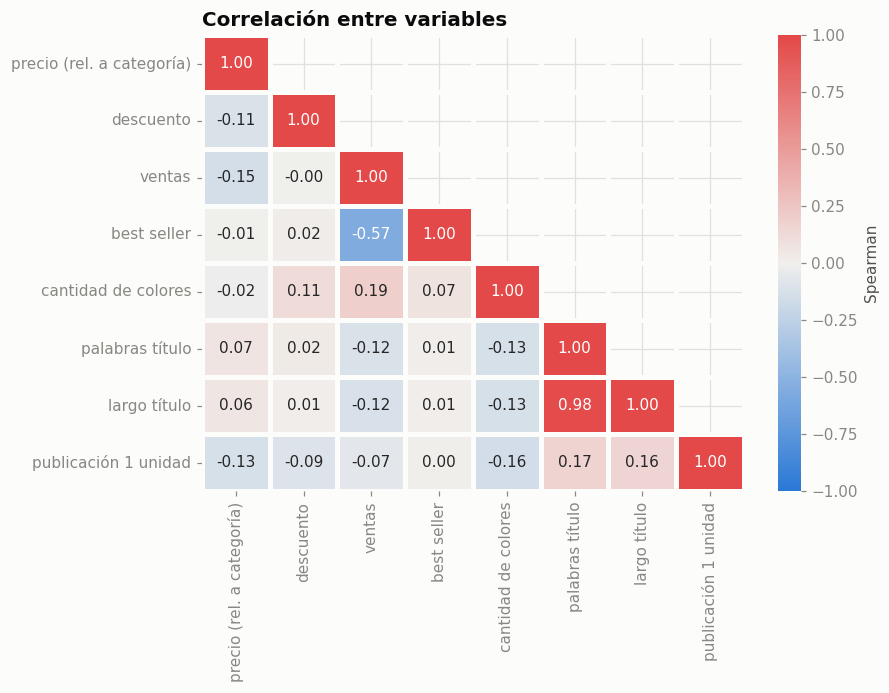

In [ ]:
# Paso 6: matriz de correlación entre las variables numéricas
# Diccionario: nombre de la columna -> nombre legible para el gráfico
nombres = {"log_precio_rel": "precio (rel. a categoría)", "descuento": "descuento", "log_vendidos": "ventas", "es_bestseller": "best seller",
           "colores": "cantidad de colores", "n_palabras": "palabras título", "largo_nombre": "largo título", "es_1pc": "publicación 1 unidad"}
corr = df[list(nombres)].rename(columns=nombres).corr(method="spearman")   # correlación de cada par de variables

fig, ax = plt.subplots(figsize=(8.2, 6.4))
# Mapa de calor: rojo = suben juntas, azul = una sube y la otra baja
# mask oculta la mitad de arriba (es la misma información que la de abajo, repetida)
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap=DIV,
            vmin=-1, vmax=1, center=0, linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "Spearman"}, ax=ax)
ax.tick_params(axis="y", rotation=0); ax.set_title("Correlación entre variables")
plt.tight_layout(); plt.show()

Cada celda muestra la correlación entre dos variables. El rojo indica que tienden a aumentar juntas, el azul que una aumenta mientras la otra disminuye y los tonos claros que hay poca relación entre ellas.

Podemos fijarnos especialmente en la fila de precio_rel para ver con qué variables se relaciona más y si esa relación es positiva o negativa. También hay que prestar atención a las correlaciones altas entre variables distintas del precio. Por ejemplo, `n_palabras` y `largo_nombre` pueden estar muy relacionadas porque ambas reflejan características de la longitud del título.

Estas relaciones no significan que una variable cause cambios en la otra. Además, la matriz permite detectar tendencias de aumento o disminución, pero no relaciones más complejas que una red neuronal podría llegar a identificar.

### Paso 7 — ¿Qué palabras del título se asocian con productos caros o baratos?
Analizamos las 80 palabras que aparecen con mayor frecuencia en los títulos de los productos. Para cada palabra, calculamos la mediana del precio relativo de los productos que la contienen y mostramos las ocho más asociadas a precios altos y las ocho más asociadas a precios bajos.

El objetivo es ver si ciertas palabras de los títulos suelen aparecer en productos más caros o más baratos que lo habitual para su categoría. Usamos el precio relativo para poder comparar productos de distintos tipos: un valor de 1 representa el precio típico de la categoría, uno mayor que 1 indica un precio superior y uno menor que 1, un precio inferior.

Esto nos da una idea de qué palabras podrían aportar información útil para que la red neuronal pueda predecir el nivel de precio de un producto.

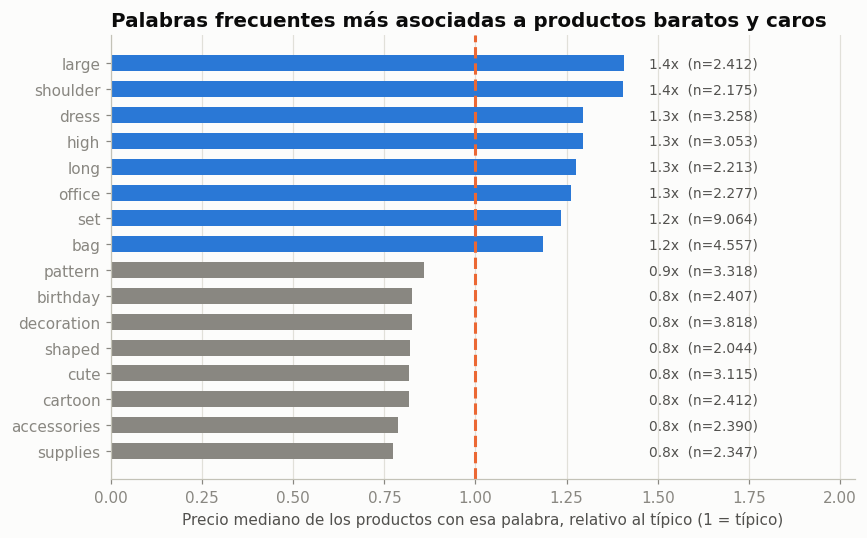

In [ ]:
# Paso 7: palabras del título asociadas a productos caros o baratos
# CountVectorizer arma una columna por palabra frecuente (las 80 más comunes que aparecen en 300+ títulos),
# ignorando palabras vacías del inglés ("the", "and", "for"...)
cv_pal = CountVectorizer(binary=True, stop_words="english", token_pattern=PALABRAS, min_df=300, max_features=80)
Xp = cv_pal.fit_transform(df["nombre"])                  # matriz 0/1: ¿el título contiene la palabra?
palabras = cv_pal.get_feature_names_out()                # lista de las 80 palabras
# Para cada palabra: precio relativo mediano de los productos que la tienen en el título
ratio = pd.Series({p: df.loc[Xp[:, i].toarray().ravel() > 0, "precio_rel"].median() for i, p in enumerate(palabras)})
frec = pd.Series(np.asarray(Xp.sum(axis=0)).ravel(), index=palabras)   # en cuántos títulos aparece cada palabra
ratio = pd.concat([ratio.nsmallest(8), ratio.nlargest(8)]).sort_values()      # las 8 más baratas y las 8 más caras

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(ratio.index, ratio.values, color=[AZUL if r >= 1 else GRIS for r in ratio.values], height=0.62)   # azul = más cara que lo típico, gris = más barata
ax.axvline(1, color=NARANJA, linestyle="--")             # línea del precio típico
x_lab = ratio.max() * 1.05                    # columna fija de rótulos, a la derecha de todas las barras
for y, (p, r) in enumerate(ratio.items()):
    ax.text(x_lab, y, f"{r:.1f}x  (n={num(frec[p])})", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, ratio.max() * 1.45); ax.set_xlabel("Precio mediano de los productos con esa palabra, relativo al típico (1 = típico)")
ax.set_title("Palabras frecuentes más asociadas a productos baratos y caros")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Cada barra representa una palabra y muestra la mediana del precio relativo de los productos cuyos títulos la contienen. El valor de `n` indica en cuántos títulos aparece esa palabra. La línea naranja marca el valor 1, que corresponde al precio típico de la categoría.

Las barras azules representan palabras asociadas con productos más caros de lo habitual para su categoría, mientras que las grises corresponden a productos más baratos. Si una palabra tiene un valor cercano a 1, no parece diferenciar demasiado los precios; por eso nos centramos en las que muestran mayores diferencias.

De todos modos, esto es solo una referencia. La red neuronal no analiza cada palabra por separado, sino que combina la información de muchas palabras para hacer sus predicciones.

## 4. Técnica 1 — K-Means (clustering)
Usamos K-Means para agrupar los productos según cuatro características: el precio relativo a su categoría (en logaritmo), el descuento, las ventas (en logaritmo) y la cantidad de palabras del título. No incluimos el título completo ni el ranking en el agrupamiento, porque queremos utilizarlos después para entender qué caracteriza a cada grupo.

K-Means es una técnica no supervisada, es decir, no le indicamos de antemano qué grupos debe encontrar. El algoritmo busca agrupar productos con características similares para ver qué segmentos aparecen y si tienen sentido desde el punto de vista comercial.

Usamos el precio relativo a la categoría en lugar del precio en dólares para evitar que las diferencias habituales entre categorías condicionen demasiado los grupos. Por ejemplo, un anillo de 2 dólares y un zapato de 12 pueden tener precios normales para sus respectivas categorías.

Cómo funciona K-Means:
1. Elegimos K, que indica cuántos grupos queremos formar.
2. Se ubican inicialmente K centros.
3. Cada producto se asigna al centro más cercano.
4. Se recalculan los centros según los productos asignados y se repite el proceso hasta que los grupos dejan de cambiar.
Antes de aplicarlo, también tenemos que estandarizar las variables. Como K-Means calcula distancias, las variables con valores numéricos más grandes podrían tener demasiado peso en el resultado. Por eso escalamos el descuento y la cantidad de palabras del título. El precio relativo y las ventas ya están transformados mediante logaritmos para reducir el efecto de los valores extremos.

In [ ]:
# =====================================================================
# 4. TÉCNICA 1 — K-MEANS: preparación de la matriz de entrada
# =====================================================================
feat_k = ["log_precio_rel", "descuento", "log_vendidos", "n_palabras"]   # las 4 variables que usa K-Means
# Estandarizamos: así ninguna variable pesa más solo por estar en una escala más grande
X_scaled = StandardScaler().fit_transform(dfm[feat_k])          # media 0 y desvío 1 en cada columna
SIL_N = min(10_000, len(X_scaled) - 1)                          # la silueta se calcula sobre una submuestra (es lenta)
print("Matriz lista para K-Means:", X_scaled.shape)

Matriz lista para K-Means: (30000, 4)


**Cómo leer el resultado:** tenemos una matriz con una fila por producto y 4 columnas, ya estandarizada.

### 4.1 ¿Cuántos clusters (K)? Método del codo + silueta
Probamos distintas cantidades de grupos, desde K = 2 hasta K = 8, y evaluamos los resultados con dos métricas: la inercia y el coeficiente de silueta.

La inercia mide qué tan cerca están los productos de sus respectivos centros. A medida que agregamos grupos, siempre disminuye, por lo que buscamos el punto de la curva donde empieza a bajar más lentamente. Ese punto se conoce como el codo.

El coeficiente de silueta, en cambio, permite evaluar qué tan bien agrupados y separados están los productos. Cuanto más alto es su valor, mejor definidos están los grupos.

Combinamos ambas métricas para elegir una cantidad de clusters razonable, aunque ninguna determina por sí sola una respuesta única.

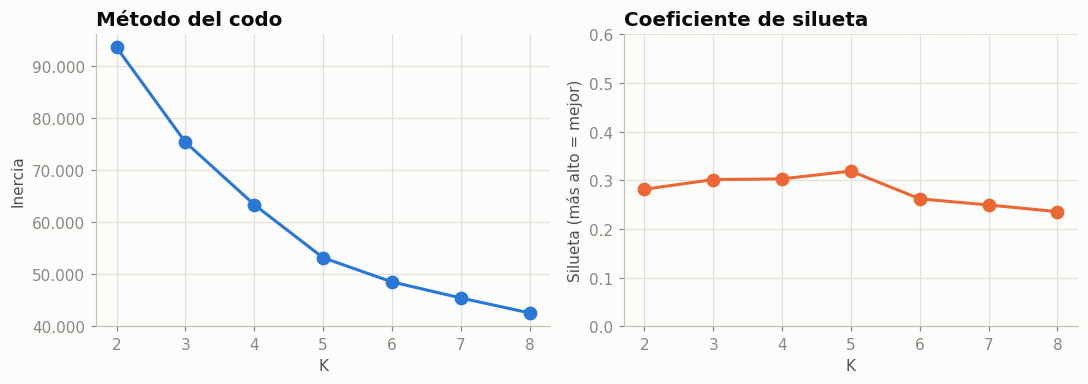

,K,inercia,silueta
0,2,93614.0,0.281
1,3,75358.0,0.301
2,4,63332.0,0.303
3,5,53104.0,0.319
4,6,48442.0,0.262
5,7,45353.0,0.249
6,8,42466.0,0.235


In [ ]:
# 4.1 Elegir K: probamos de 2 a 8 clusters y medimos inercia y silueta en cada caso
ks = list(range(2, 9))                 # valores de K a probar: 2, 3, ..., 8
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled)   # n_init=10: prueba 10 inicios y se queda con el mejor
    inercia.append(km.inertia_)   # inercia: suma de distancias al centro de cada grupo (menor = más compactos)
    silueta.append(silhouette_score(X_scaled, km.labels_, sample_size=SIL_N, random_state=SEED))   # de -1 a 1, más alto = mejor

# Dos gráficos lado a lado: método del codo (izq.) y silueta (der.)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(ks, inercia, marker="o", markersize=8, color=AZUL)
axs[0].set_title("Método del codo"); axs[0].set_xlabel("K"); axs[0].set_ylabel("Inercia")
axs[0].yaxis.set_major_formatter(miles)
axs[1].plot(ks, silueta, marker="o", markersize=8, color=NARANJA)
axs[1].set_title("Coeficiente de silueta"); axs[1].set_xlabel("K"); axs[1].set_ylabel("Silueta (más alto = mejor)")
axs[1].set_ylim(0, 0.6)       # escala completa: evita que diferencias mínimas parezcan enormes
plt.tight_layout(); plt.show()
# Tabla con los mismos valores
pd.DataFrame({"K": ks, "inercia": np.round(inercia, 0), "silueta": np.round(silueta, 3)})

El gráfico del codo (azul) sirve para buscar el punto donde la curva empieza a bajar más lentamente. Si no se distingue un quiebre claro, puede ser que los datos no tengan grupos bien definidos.

La curva de silueta (naranja) permite comparar qué tan separados están los grupos. Como referencia, un valor de 0,5 o más suele indicar una buena separación; entre 0,25 y 0,5, una separación moderada; y por debajo de 0,25, grupos bastante solapados.

Para elegir la cantidad de clusters, el código selecciona automáticamente el valor de K con la silueta más alta entre 3 y 5. Así evitamos quedarnos con solo dos grupos, que podrían ser poco útiles para el análisis, o crear tantos que después resulte difícil interpretarlos en la defensa.

### 4.2 Entrenamiento
Entrenamos K-Means con la cantidad de grupos que elegimos y asignamos cada producto al cluster correspondiente.

Como el algoritmo les pone números a los grupos de manera arbitraria, esa numeración no indica si un grupo es más barato o más caro que otro. Para que sea más fácil interpretarlos, ordenamos los clusters según la mediana del precio relativo de sus productos. Así, el Cluster 1 corresponde al grupo con los precios más bajos en relación con sus categorías, y los siguientes se ordenan de menor a mayor.

In [ ]:
# 4.2 Entrenamiento del K-Means definitivo
candidatos = [(k, s_) for k, s_ in zip(ks, silueta) if 3 <= k <= 5]      # solo K entre 3 y 5
K = max(candidatos, key=lambda t: t[1])[0]                                  # el de mejor silueta
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_scaled)
dfm["cluster"] = kmeans.labels_                # guardamos en qué cluster quedó cada producto (0, 1, 2...)

# Renombramos los clusters ordenándolos por precio relativo mediano (Cluster 1 = más baratos)
orden_cl = dfm.groupby("cluster")["precio_rel"].median().sort_values().index
dfm["cluster"] = dfm["cluster"].map({old: f"Cluster {i+1}" for i, old in enumerate(orden_cl)})

sil = silhouette_score(X_scaled, kmeans.labels_, sample_size=SIL_N, random_state=SEED)   # calidad del agrupamiento final
print(f"K elegido: {K} | silueta: {sil:.3f}")
dfm["cluster"].value_counts().sort_index()     # cantidad de productos en cada cluster

K elegido: 5 | silueta: 0.319


,count
cluster,
Cluster 1,4292
Cluster 2,13967
Cluster 3,6824
Cluster 4,2608
Cluster 5,2309


**Cómo leer el resultado:** muestra el K elegido, la silueta final y cuántos productos cayeron en cada cluster. Los clusters **no tienen por qué ser del mismo tamaño**: K-Means agrupa por parecido, no por cantidad.

### 4.3 Visualización de los clusters (PCA a 2 dimensiones)
Como estamos trabajando con cuatro variables, usamos PCA para reducirlas a dos componentes y poder representar los productos en un gráfico de dos dimensiones. Cada punto representa un producto y el color indica a qué cluster pertenece. Para que el gráfico sea más fácil de leer, mostramos una muestra de hasta 5.000 productos.

PCA busca conservar la mayor cantidad posible de información de las variables originales en esas dos dimensiones. De esta manera, podemos observar cómo se distribuyen los grupos y cuánto se separan entre sí, aunque parte de la información se pierde al reducir las dimensiones.

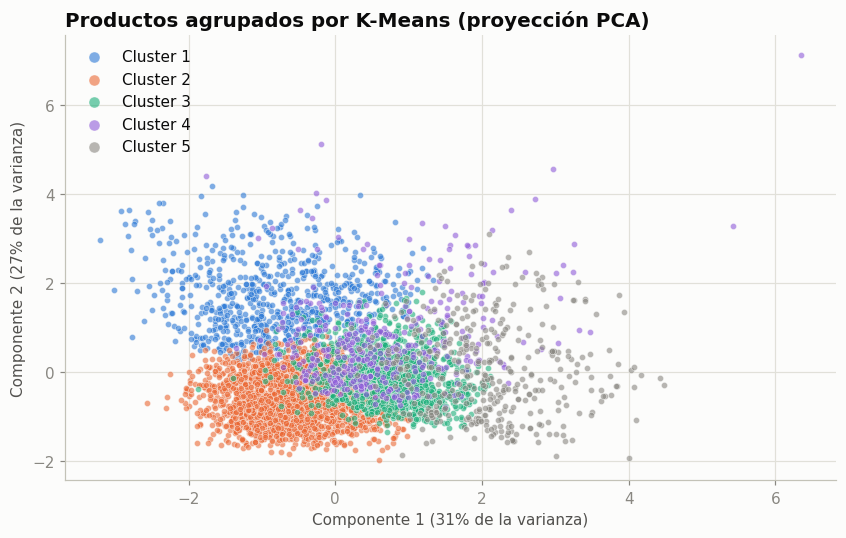

In [ ]:
# 4.3 Visualización: PCA resume las 4 variables en 2 ejes para poder dibujar los clusters en un plano
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_scaled)                  # coordenadas (x, y) de cada producto
nombres_cl = sorted(dfm["cluster"].unique())          # ["Cluster 1", "Cluster 2", ...]
CL_COL = dict(zip(nombres_cl, CL_COLORS))             # un color para cada cluster
idx = np.random.default_rng(SEED).choice(len(dfm), size=min(5000, len(dfm)), replace=False)   # muestra para dibujar

fig, ax = plt.subplots(figsize=(7.8, 5))
for cl in nombres_cl:                                 # dibujamos los puntos de cada cluster con su color
    m = (dfm["cluster"].values[idx] == cl)            # filtro: productos de la muestra que pertenecen a este cluster
    ax.scatter(coords[idx][m, 0], coords[idx][m, 1], s=16, color=CL_COL[cl], alpha=0.6,
               edgecolor="#fcfcfb", linewidth=0.4, label=cl)
# En cada eje mostramos qué % de la información original conserva
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%} de la varianza)")
ax.set_title("Productos agrupados por K-Means (proyección PCA)")
ax.legend(frameon=False, markerscale=1.8)
plt.tight_layout(); plt.show()

**Cómo leer el resultado:**
- Cada punto es un producto y el color es su cluster. Puntos cercanos = productos de características parecidas.
- Los ejes no son variables reales: son "mezclas" de las 4. El porcentaje de cada eje dice **cuánta información conserva**; si entre los dos suman bastante (más de ~60%), el dibujo es una buena representación.
- Mirá si los clusters forman **zonas separadas** o **se mezclan en los bordes**. Si se mezclan, hay una gradación continua y no cortes tajantes (coherente con una silueta moderada o baja).

### 4.4 ¿Cómo es cada cluster? (perfil)
Armamos una tabla con las características de cada cluster y un mapa de calor para comparar sus valores con el promedio general.

Esto nos permite entender qué distingue a cada grupo y qué tienen en común sus productos. En el mapa de calor, el rojo indica valores por encima del promedio y el azul, valores por debajo. Las diferencias se expresan en desvíos estándar y se calculan con las variables transformadas que utilizó K-Means. Así podemos identificar, por ejemplo, qué grupos tienen precios relativos, descuentos o ventas más altos o más bajos que lo habitual.

,n,precio_rel_mediano,precio_mediano,pct_con_descuento,pct_con_ventas,palabras_titulo,pct_1pc,pct_bestseller,pct_caro
cluster,,,,,,,,,
Cluster 1,4292,0.56,2.75,100.0,74.0,15.0,27.0,14.0,9.0
Cluster 2,13967,0.98,5.70,61.0,100.0,13.0,20.0,0.0,30.0
Cluster 3,6824,1.04,5.90,54.0,10.0,14.0,22.0,61.0,33.0
Cluster 4,2608,1.09,4.30,62.0,86.0,35.0,30.0,10.0,35.0
Cluster 5,2309,6.98,32.99,70.0,33.0,20.0,13.0,15.0,100.0


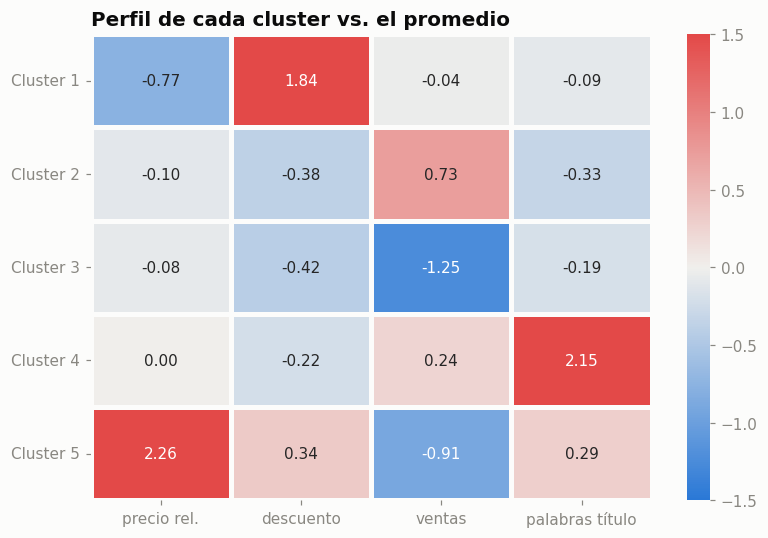

In [ ]:
# 4.4 Perfil de cada cluster: valores típicos de cada grupo en sus unidades originales
perfil = dfm.groupby("cluster").agg(
    n=("precio", "size"), precio_rel_mediano=("precio_rel", "median"), precio_mediano=("precio", "median"), pct_con_descuento=("tiene_descuento", "mean"),
    pct_con_ventas=("tiene_vendidos", "mean"), palabras_titulo=("n_palabras", "median"),
    pct_1pc=("es_1pc", "mean"), pct_bestseller=("es_bestseller", "mean"), pct_caro=("nivel_precio", lambda s: (s == "Caro").mean())
).round(2)
# Las columnas "pct_" son proporciones (0 a 1): las pasamos a porcentaje
for c in ["pct_con_descuento", "pct_con_ventas", "pct_1pc", "pct_bestseller", "pct_caro"]:
    perfil[c] = (perfil[c] * 100).round(0)
display(perfil)

# Centroides en el espacio estandarizado: cuánto se aleja cada cluster del promedio general
# (0 = igual al promedio, positivo = por encima, negativo = por debajo)
z = pd.DataFrame(X_scaled, columns=["precio rel.", "descuento", "ventas", "palabras título"]).groupby(dfm["cluster"].values).mean()
fig, ax = plt.subplots(figsize=(7.4, 1.0 + 0.8 * len(z)))     # la altura crece según la cantidad de clusters
sns.heatmap(z, annot=True, fmt=".2f", cmap=DIV, center=0, vmin=-1.5, vmax=1.5,
            linewidths=2, linecolor="#fcfcfb", ax=ax)
ax.set_ylabel(""); ax.tick_params(axis="y", rotation=0); ax.set_title("Perfil de cada cluster vs. el promedio")
plt.tight_layout(); plt.show()

La tabla muestra los valores típicos de cada cluster en sus unidades originales, como dólares, porcentajes y cantidad de palabras. Las columnas `pct_1pc`, `pct_bestseller` y `pct_caro` no se usaron para formar los grupos; las agregamos después para entender mejor sus características.

En el mapa de calor, conviene fijarse en las celdas más rojas y más azules de cada cluster, porque muestran qué variables están más por encima o por debajo del promedio. Esto ayuda a describir los grupos con nombres que resuman sus características, como «productos baratos con muchas ventas» o «productos caros con descuento», si los resultados muestran ese patrón.

Los clusters no necesariamente se diferencian por una sola variable. Muchas veces, lo que distingue a un grupo es la combinación de varias características, como un precio bajo junto con un nivel alto de ventas.

### 4.5 ¿Los clusters se parecen a los niveles de precio?
En este paso cruzamos los clusters con los niveles de precio (Barato, Medio y Caro) mediante una tabla de porcentajes que se muestra como mapa de calor. También calculamos la pureza, que indica qué porcentaje de los productos de cada cluster pertenece al nivel de precio más frecuente dentro de ese grupo.

Esto sirve para ver cuánto se relacionan los clusters con el precio. Como el precio relativo es una de las variables utilizadas para formar los grupos, es esperable que influya en cómo se organizan. Sin embargo, si dentro de un mismo cluster aparecen productos de distintos niveles, significa que los grupos también pueden estar diferenciándose por otras características, como los descuentos, las ventas o el largo de los títulos.

Para interpretar la pureza, la comparamos con un valor de referencia: el porcentaje que representa la clase más común en todo el conjunto de datos. Si la pureza de los clusters supera ese valor, significa que los grupos concentran mejor los niveles de precio que una clasificación sin ningún criterio.


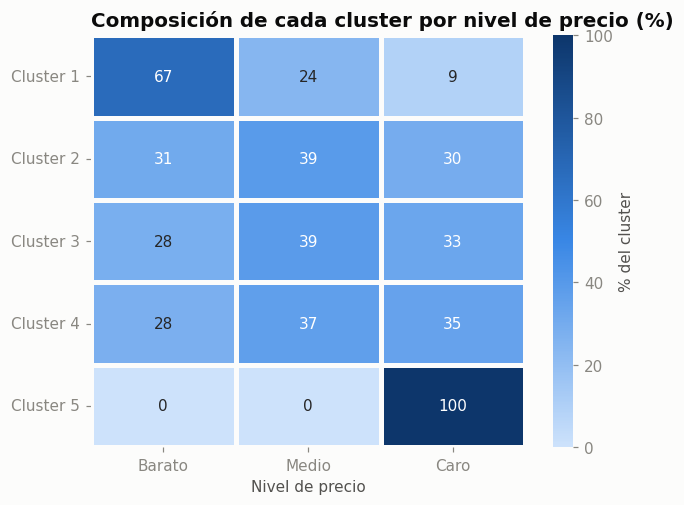

Pureza: 48% de los productos caen en el nivel dominante de su cluster
Sin ningún criterio la pureza sería ≈ 34% (proporción de la clase más común)


In [ ]:
# 4.5 Cruzamos clusters con niveles de precio
# Tabla cruzada: qué % de cada cluster es Barato, Medio o Caro
tabla = pd.crosstab(dfm["cluster"], dfm["nivel_precio"], normalize="index")[["Barato", "Medio", "Caro"]]   # cada fila suma 100%
fig, ax = plt.subplots(figsize=(6, 1.2 + 0.7 * len(tabla)))
sns.heatmap(tabla * 100, annot=True, fmt=".0f", cmap=SEC, vmin=0, vmax=100,
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "% del cluster"}, ax=ax)
ax.set_xlabel("Nivel de precio"); ax.set_ylabel(""); ax.tick_params(axis="y", rotation=0)
ax.set_title("Composición de cada cluster por nivel de precio (%)")
plt.tight_layout(); plt.show()

# Pureza: % de productos que pertenecen al nivel más común de su cluster (1 = cada cluster tiene un solo nivel)
pureza = pd.crosstab(dfm["cluster"], dfm["nivel_precio"]).max(axis=1).sum() / len(dfm)
azar = dfm["nivel_precio"].value_counts(normalize=True).max()   # referencia: la pureza sin agrupar (≈ 33%)
print(f"Pureza: {pureza:.0%} de los productos caen en el nivel dominante de su cluster")
print(f"Sin ningún criterio la pureza sería ≈ {azar:.0%} (proporción de la clase más común)")

Cada fila representa un cluster y suma 100%. Cuanto más oscura sea una celda, mayor es la proporción de productos de ese nivel de precio dentro del grupo.

Si una celda concentra casi todo el porcentaje de la fila, significa que predomina un nivel de precio. En cambio, si los porcentajes son parecidos, el cluster combina productos baratos, medios y caros.

La comparación entre la pureza y el valor de referencia permite ver cuánto se relacionan los clusters con los niveles de precio. Es esperable que haya cierta relación porque el precio se usó para formar los grupos. Por eso, también interesa observar qué productos quedan mezclados y si los descuentos, las ventas o los títulos ayudan a diferenciarlos.

### 4.6 ¿Qué productos hay en cada cluster? (palabras características)
En este paso buscamos las palabras de los títulos que aparecen con mayor frecuencia en cada cluster en comparación con el conjunto completo. También mostramos algunos títulos de ejemplo para entender qué tipo de productos hay en cada grupo.

Como los títulos no se usaron para formar los clusters, analizarlos permite comprobar si los grupos tienen características reconocibles. Por ejemplo, si en un cluster aparecen con frecuencia palabras como "refrigerator" o "massage", puede indicar que reúne productos de ese tipo, aunque K-Means no haya utilizado sus nombres para agruparlos.

Para medir esta diferencia usamos el lift, que indica cuántas veces más frecuente es una palabra dentro de un cluster que en el conjunto total. Solo tenemos en cuenta las palabras que aparecen en al menos el 5% de los títulos de ese grupo, para evitar destacar términos demasiado poco frecuentes.

In [ ]:
# 4.6 Palabras características de cada cluster
# Matriz 0/1 de palabras (las que aparecen en al menos 15 títulos de la muestra)
cv_cl = CountVectorizer(binary=True, stop_words="english", token_pattern=PALABRAS, min_df=15)
Xc = cv_cl.fit_transform(dfm["nombre"]).tocsc()
vocab = cv_cl.get_feature_names_out()                 # lista de palabras
p_total = np.asarray(Xc.mean(axis=0)).ravel()         # % de títulos de toda la muestra que tienen cada palabra

filas = []
for cl in nombres_cl:
    m = (dfm["cluster"] == cl).values                 # filtro: productos de este cluster
    p_cl = np.asarray(Xc[m].mean(axis=0)).ravel()     # % de títulos del cluster que tienen cada palabra
    # lift = cuántas veces más frecuente es la palabra en el cluster que en el total (lift 3 = el triple)
    lift = np.where(p_cl >= 0.05, p_cl / p_total, 0)            # solo palabras presentes en >= 5% de los títulos del cluster
    top = [vocab[i] for i in np.argsort(-lift)[:7] if lift[i] > 0]   # las 7 palabras con mayor lift
    ejemplos = dfm.loc[m, "nombre"].sample(2, random_state=SEED).str.slice(0, 60).tolist()   # 2 títulos de ejemplo (cortados a 60 caracteres)
    filas.append({"cluster": cl, "palabras características": ", ".join(top), "ejemplos de títulos": " | ".join(ejemplos)})
pd.set_option("display.max_colwidth", 140)            # más ancho para que se lean los ejemplos
pd.DataFrame(filas).set_index("cluster")

,palabras características,ejemplos de títulos
cluster,,
Cluster 1,"outdoor, men, portable, decoration, size, party, gift",SHEIN Essnce Women's Heart-Shaped Printed Loose Fit Asymmetr | Cat/dog Cowboy Hat Mini Size Pet Costume Accessory
Cluster 2,"girl, sleeve, shein, shorts, shirt, baby, neck",SHEIN LUNE Plus Size Striped Printed Casual Daily Wear Pants | 4pcs Neutral Baby Simple Swaddle Blanket
Cluster 3,"men, pet, size, plus, solid, shorts, color","SHEIN Plus Size Bralette & Wireless Bra | 1PC Men's Wallet, Short Wallet, Business Casual Style Pu Mat"
Cluster 4,"mom, essentials, dorm, college, gifts, friends, business","TOMICCA Peach-Colored Builder Gel 5-In-1, 15ml Per Bottle, Q | 1pc, Multifunctional Luncheon Meat Cutter, Stainless Steel E"
Cluster 5,"unbeatablesale, inch, indoor, electric, adjustable, cat, dog","Mother And Child 2pcs Backpack Set With Pencil Case, Pen Bag | 1pc Claw Clip Kinky Straight Ponytail Human Hair Extension N"


Cada fila corresponde a un cluster y muestra las palabras que más lo diferencian del resto, junto con dos títulos elegidos al azar como ejemplo.

Si las palabras se relacionan con un mismo tipo de producto o estilo de publicación, el grupo puede tener un sentido comercial. Por ejemplo, si aparece mucho «1pc», podría tratarse de publicaciones de accesorios pequeños.

En cambio, si las palabras son muy generales o se repiten entre varios clusters, es posible que los grupos se diferencien principalmente por el precio, los descuentos y las ventas, y no tanto por el tipo de producto.

Estos resultados ayudan a identificar las características de cada grupo y elegir un nombre que las resuma para explicarlo en la defensa.

### 4.7 ¿Los segmentos son lo mismo que las categorías?
En este paso mostramos qué porcentaje de los productos de cada categoría pertenece a cada cluster. Los resultados se presentan en un mapa de calor y cada fila suma 100%.

Como usamos el precio relativo a la categoría para formar los clusters, buscamos comprobar si los grupos representan algo más que el tipo de producto. Si las categorías se distribuyen de manera similar entre los distintos clusters, significa que los segmentos reúnen productos de diferentes categorías y reflejan características de venta en común.

En cambio, si una categoría concentra gran parte de sus productos en un solo cluster, puede indicar que ese grupo está más relacionado con esa categoría en particular.

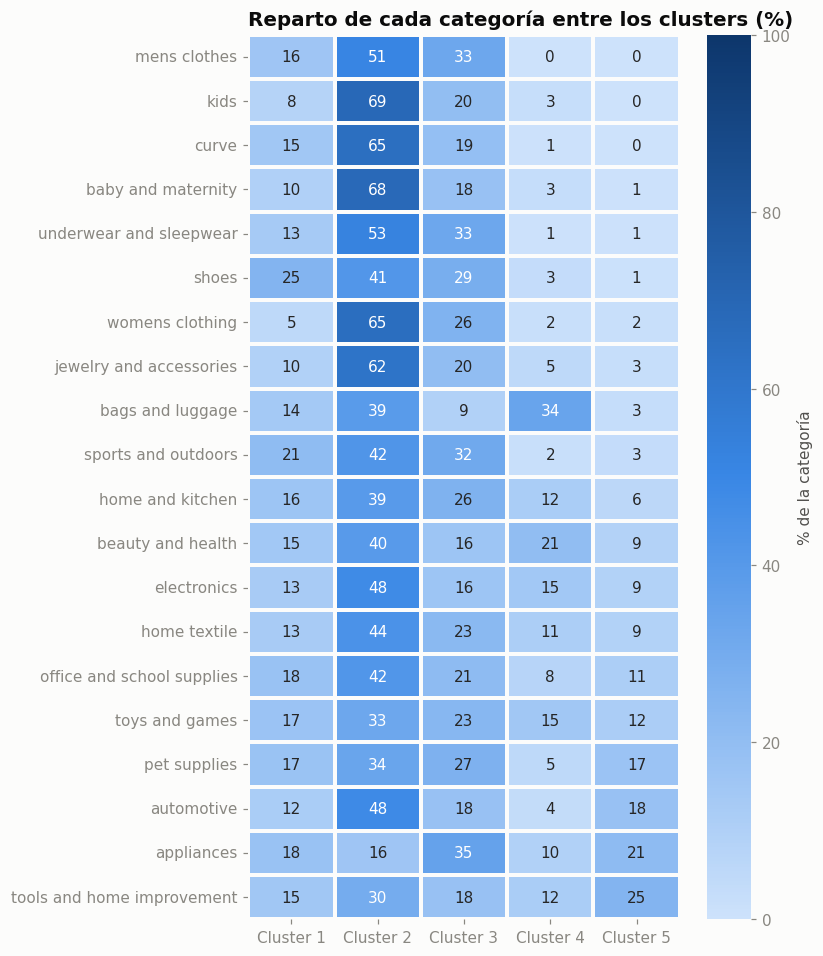

In [ ]:
# 4.7 ¿Los clusters son lo mismo que las categorías? Vemos cómo se reparte cada categoría entre los clusters
comp_cat = pd.crosstab(dfm["categoria"], dfm["cluster"], normalize="index") * 100   # cada fila (categoría) suma 100%
comp_cat = comp_cat.sort_values(comp_cat.columns[-1])           # ordenamos por el % en el último cluster
fig, ax = plt.subplots(figsize=(7.4, 0.36 * len(comp_cat) + 1.6))   # alto según la cantidad de categorías
sns.heatmap(comp_cat, annot=True, fmt=".0f", cmap=SEC, vmin=0, vmax=100,
            linewidths=1.5, linecolor="#fcfcfb", cbar_kws={"label": "% de la categoría"}, ax=ax)
ax.set_ylabel(""); ax.set_xlabel(""); ax.tick_params(axis="y", rotation=0)
ax.set_title("Reparto de cada categoría entre los clusters (%)")
plt.tight_layout(); plt.show()

Cada fila representa una categoría y suma 100%, mientras que cada columna corresponde a un cluster. Cuanto más oscura sea una celda, mayor es el porcentaje de productos de esa categoría que pertenece a ese grupo.

Si las filas tienen colores parecidos, significa que las categorías se distribuyen de forma similar entre los clusters y que los grupos no dependen demasiado del tipo de producto.

En cambio, si una categoría tiene una celda mucho más oscura que las demás, quiere decir que concentra una mayor proporción de sus productos en ese cluster. Esto puede indicar que comparte ciertas características de venta, como tener ventas visibles o utilizar pocos descuentos.

Con este gráfico podemos evaluar si los segmentos se diferencian principalmente por cómo se venden los productos o por qué tipo de productos se venden.

## 5. Técnica 2 — Red neuronal con retropropagación (perceptrón multicapa)
Red neuronal: predicción del nivel de precio
Entrenamos una red neuronal para predecir si un producto es Barato, Medio o Caro en relación con su categoría. Para hacerlo, usamos información de los títulos, los descuentos, las ventas, si es Best Seller, si la publicación corresponde a una sola unidad, la cantidad de colores y la cantidad de palabras del título. Ni el precio ni la categoría se incluyen como datos de entrada.

A diferencia de K-Means, esta técnica es supervisada: la red aprende a partir de productos cuyo nivel de precio ya conocemos. Así podemos evaluar hasta qué punto es posible predecirlo sin utilizar directamente el precio y qué información resulta más útil.

Cómo está formada la red
- Capa de entrada: recibe las 300 palabras más frecuentes de los títulos, representadas con valores 0 o 1 según aparezcan o no, junto con las variables numéricas.
- Capas ocultas: tiene dos capas, una de 64 neuronas y otra de 32. Cada neurona combina la información recibida mediante pesos y aplica la función ReLU, que permite aprender relaciones más complejas.
- Capa de salida: tiene tres neuronas, una por cada nivel de precio. La clase con mayor probabilidad es la que predice la red.
Cómo aprende mediante retropropagación

El entrenamiento repite cuatro pasos en cada época:
1. Predicción: la red recibe los datos de un producto y calcula su nivel de precio probable.
2. Cálculo del error: compara la predicción con el nivel real y calcula la pérdida, que indica qué tan equivocada fue.
3. Retropropagación: el error se transmite desde la salida hacia las capas anteriores para calcular cuánto debe ajustarse cada peso.
4. Actualización de los pesos: el optimizador Adam modifica los pesos para intentar reducir el error en las siguientes predicciones.
Este proceso se repite durante el entrenamiento para que la red vaya mejorando sus predicciones a partir de los ejemplos disponibles.

### 5.1 Armado de datos y partición entrenamiento/prueba (70% / 30%)
Durante la preparación, `CountVectorizer` convierte las 300 palabras más frecuentes de los títulos en columnas con valores 0 o 1, según aparezca cada palabra. El vocabulario se aprende únicamente con los datos de entrenamiento, para evitar que la información del conjunto de prueba influya en esa etapa.

También estandarizamos las variables numéricas para que las diferencias de escala no dificulten el aprendizaje de la red.

La separación entre entrenamiento y prueba permite comprobar si la red puede predecir correctamente productos que no vio durante el entrenamiento. Si evaluáramos con los mismos datos que utilizó para aprender, podría obtener buenos resultados simplemente por memorizarlos, sin lograr generalizar a nuevos casos. Con stratify=y, mantenemos proporciones similares de productos Baratos, Medios y Caros en ambos conjuntos.

Por último, usamos early stopping: se reserva una parte de los datos de entrenamiento para controlar el rendimiento y se detiene el proceso cuando la red deja de mejorar. Esto ayuda a evitar el sobreajuste, que ocurre cuando aprende demasiado bien los ejemplos de entrenamiento, pero tiene dificultades con datos nuevos.

In [ ]:
# =====================================================================
# 5. TÉCNICA 2 — RED NEURONAL: armado de datos y partición 70/30
# =====================================================================
NUM = ["descuento", "log_vendidos", "es_bestseller", "es_1pc", "colores", "n_palabras"]     # OJO: sin precio ni nada calculado con el precio

# Función que arma la red completa (preparación de datos + red), para poder reutilizarla con distintas configuraciones
#   num:   lista de variables numéricas a usar
#   texto: True = también usa las palabras del título
#   capas: neuronas de cada capa oculta, ej. (64, 32) = 2 capas de 64 y 32 neuronas
def armar_red(num=NUM, texto=True, capas=(64, 32)):
    bloques = []
    if num:
        bloques.append(("num", StandardScaler(), num))                           # variables numéricas, estandarizadas
    if texto:
        bloques.append(("txt", CountVectorizer(max_features=300, binary=True, stop_words="english",
                                               min_df=15, token_pattern=PALABRAS), "nombre"))   # palabras -> columnas 0/1
    # Red neuronal (perceptrón multicapa) que aprende por retropropagación:
    #   activation="relu": función de activación de las neuronas | solver="adam": método para ajustar los pesos
    #   alpha: penalización que reduce el sobreajuste
    #   early_stopping: separa un 15% para validar y frena si en 10 épocas seguidas no mejora
    #   max_iter=300: como máximo 300 épocas
    mlp = MLPClassifier(hidden_layer_sizes=capas, activation="relu", solver="adam", alpha=1e-3,
                        early_stopping=True, validation_fraction=0.15, n_iter_no_change=10,
                        max_iter=300, random_state=SEED)
    # Pipeline: primero prepara los datos ("prep") y después entrena la red ("mlp")
    return Pipeline([("prep", ColumnTransformer(bloques)), ("mlp", mlp)])

X = dfm[NUM + ["nombre"]]                       # entradas: variables numéricas + título
NIVELES = ["Barato", "Medio", "Caro"]
y = dfm["nivel_precio"].astype(str).map({n: i for i, n in enumerate(NIVELES)})   # 0 = Barato, 1 = Medio, 2 = Caro (números: algunas versiones de scikit-learn fallan con texto)
# 70% para entrenar y 30% para probar; stratify=y mantiene la misma proporción de cada nivel en ambas partes
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
print("Entrenamiento:", X_tr.shape, "| Prueba:", X_te.shape)
print("Variables numéricas:", NUM, "+ palabras del título")

Entrenamiento: (21000, 7) | Prueba: (9000, 7)
Variables numéricas: ['descuento', 'log_vendidos', 'es_bestseller', 'es_1pc', 'colores', 'n_palabras'] + palabras del título


**Cómo leer el resultado:** vemos cuántos productos hay para entrenar y para probar, y qué variables usa la red. Fijate que **`precio` no aparece**: la red tiene que deducir el nivel solo con el título y las señales comerciales.

### 5.2 Entrenamiento y resultados
Entrenamos la red neuronal y evaluamos su rendimiento con distintas métricas para comprobar qué tan bien predice los niveles de precio y si logra funcionar con productos que no vio durante el entrenamiento.

Primero, la comparamos con un baseline, que siempre predice la clase más frecuente. Este sirve como referencia mínima: si la red no consigue superarlo, significa que no está aportando una mejora frente a una predicción muy simple.

También comparamos el accuracy de entrenamiento con el de prueba. Si el primero es mucho mayor que el segundo, puede ser una señal de sobreajuste, es decir, que la red aprendió demasiado los ejemplos de entrenamiento y tiene dificultades con productos nuevos.

Además, usamos el F1 macro, que calcula el desempeño de cada clase y después promedia los resultados dándoles la misma importancia a Barato, Medio y Caro. Esto permite evaluar las tres clases sin que la más frecuente tenga más peso.

La validación cruzada de 3 folds repite la evaluación con distintas divisiones de los datos. Así podemos comprobar si los resultados se mantienen o si dependen demasiado de una división en particular.

Por último, el reporte por clase incluye precision y recall:
- Precision: de los productos que la red clasificó como Caros, cuántos realmente eran Caros.
- Recall: de todos los productos que realmente eran Caros, cuántos logró identificar la red.
Estas métricas también se calculan para las clases Barato y Medio, lo que permite ver en cuáles funciona mejor y dónde comete más errores.

In [ ]:
# 5.2 Entrenamiento y evaluación de la red
red = armar_red().fit(X_tr, y_tr)                 # entrenamos con los datos de entrenamiento
mlp = red.named_steps["mlp"]                      # la red entrenada (para ver su historial de aprendizaje)

base = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)      # baseline: siempre la clase más común
pred = red.predict(X_te)                          # predicciones de la red sobre los datos de prueba (que nunca vio)
print(f"Baseline (siempre la clase más común): {base.score(X_te, y_te):.1%}")
print(f"Red - accuracy entrenamiento         : {red.score(X_tr, y_tr):.1%}")   # % de aciertos en datos que ya vio
print(f"Red - accuracy prueba                : {red.score(X_te, y_te):.1%}")   # % de aciertos en datos nuevos
print(f"Red - F1 macro (prueba)              : {f1_score(y_te, pred, average='macro'):.3f}")   # promedio del F1 de las 3 clases
print(f"Épocas entrenadas                    : {mlp.n_iter_}")
cv = cross_val_score(armar_red(), X, y, cv=3)     # repite el experimento con 3 particiones distintas
print(f"Validación cruzada (3 folds)         : {cv.mean():.1%} ± {cv.std():.1%}\n")
# Reporte por clase: precision, recall y F1 de Barato, Medio y Caro
print(classification_report(y_te, pred, labels=[0, 1, 2], target_names=NIVELES))

Baseline (siempre la clase más común): 33.7%
Red - accuracy entrenamiento         : 70.9%
Red - accuracy prueba                : 56.8%
Red - F1 macro (prueba)              : 0.567
Épocas entrenadas                    : 22
Validación cruzada (3 folds)         : 56.2% ± 0.6%

              precision    recall  f1-score   support

      Barato       0.59      0.65      0.62      2964
       Medio       0.48      0.44      0.46      3031
        Caro       0.62      0.62      0.62      3005

    accuracy                           0.57      9000
   macro avg       0.57      0.57      0.57      9000
weighted avg       0.57      0.57      0.57      9000



**Cómo leer el resultado:**
| Métrica | Qué significa |
|---|---|
| **Baseline** | El piso: acertar siempre la clase más común (≈ 33% si las clases están parejas) |
| **Entrenamiento** | Qué tan bien responde a lo que ya vio |
| **Prueba** | Qué tan bien responde a productos **nuevos**: es la que importa |
| **F1 macro** | Desempeño promedio de las 3 clases (de 0 a 1) |
| **Épocas** | Cuántas pasadas dio antes de frenar por *early stopping* |
| **Validación cruzada** | Promedio en 3 particiones (el ± indica cuánto varía) |

- **Lo primero:** ¿la accuracy de prueba **supera claramente al baseline**? Si sí, el título y las señales comerciales dicen algo del precio, aunque la red nunca lo vio.
- Si **entrenamiento y prueba son parecidas**, no hay sobreajuste importante; si entrenamiento es mucho mayor, la red está memorizando.
- En el reporte por clase, mirá en cuál nivel **le va mejor y peor**. Suele pasar que las **clases extremas** (Barato y Caro) se distinguen mejor que la del medio.

### 5.3 Curva de aprendizaje (cómo aprendió la red)
En este paso graficamos cómo cambia la pérdida (el error) de la red en cada época y cómo evoluciona el accuracy sobre los datos de validación.

Estos gráficos permiten observar cómo aprende la red durante el entrenamiento. Si la pérdida disminuye con las épocas, significa que está cometiendo menos errores en los datos de entrenamiento.

La curva de validación ayuda a decidir cuándo detener el entrenamiento. Si el accuracy deja de mejorar mientras la pérdida de entrenamiento sigue bajando, puede ser una señal de sobreajuste: la red sigue ajustándose a los ejemplos que ya conoce, pero no mejora sus predicciones sobre datos nuevos. Por eso usamos early stopping, que detiene el entrenamiento cuando deja de haber mejoras en la validación.

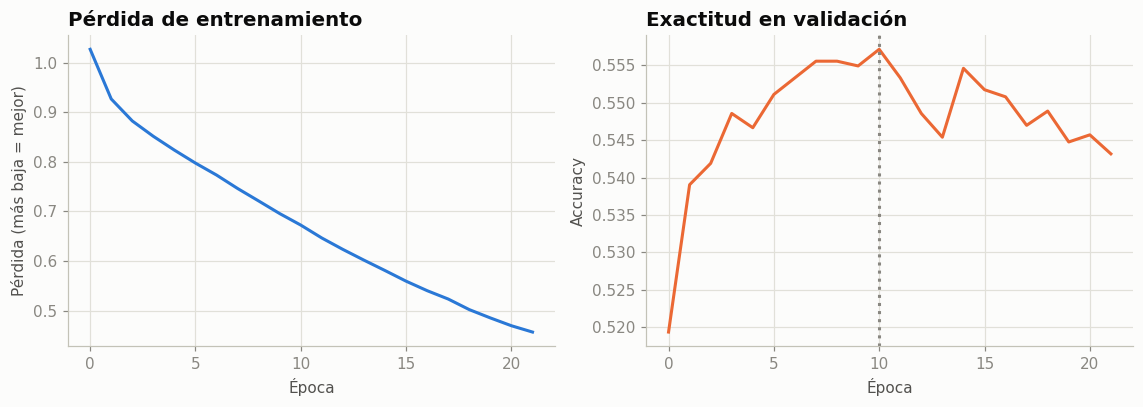

In [ ]:
# 5.3 Curva de aprendizaje: cómo fue cambiando la red época a época
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8))
axs[0].plot(mlp.loss_curve_, color=AZUL)                                   # error de entrenamiento en cada época
axs[0].set_title("Pérdida de entrenamiento"); axs[0].set_xlabel("Época"); axs[0].set_ylabel("Pérdida (más baja = mejor)")
axs[1].plot(mlp.validation_scores_, color=NARANJA)                         # exactitud (accuracy) en el 15% de validación en cada época
axs[1].axvline(int(np.argmax(mlp.validation_scores_)), color=GRIS, linestyle=":")      # época con la mejor validación
axs[1].set_title("Exactitud en validación"); axs[1].set_xlabel("Época"); axs[1].set_ylabel("Exactitud")
plt.tight_layout(); plt.show()

**Cómo leer el resultado:**
- **Izquierda (azul):** debería **bajar rápido al principio y luego aplanarse**. Eso es la red corrigiendo sus pesos por retropropagación.
- **Derecha (naranja):** la exactitud sobre datos que la red no usó para ajustar sus pesos. Sube y después se estanca o baja; la **línea punteada** marca la mejor época. Cuando pasan varias épocas sin mejorar, el *early stopping* frena el entrenamiento.
- Si la pérdida siguiera bajando pero la validación empeorara, sería señal de **sobreajuste**.

### 5.4 Matriz de confusión (¿en qué niveles se equivoca?)
En este paso mostramos una matriz de confusión que compara el nivel de precio real de cada producto con el que predijo la red, usando los datos de prueba. Las filas representan los niveles reales y las columnas, los predichos.

Esta matriz permite ver no solo cuántas predicciones fueron correctas, sino también qué errores comete la red. No es lo mismo confundir un producto Barato con uno Medio que clasificarlo como Caro, porque en el segundo caso la diferencia es mayor.

La diagonal principal muestra los aciertos, mientras que las celdas restantes representan los errores. Así podemos identificar qué niveles de precio le cuesta más distinguir a la red.

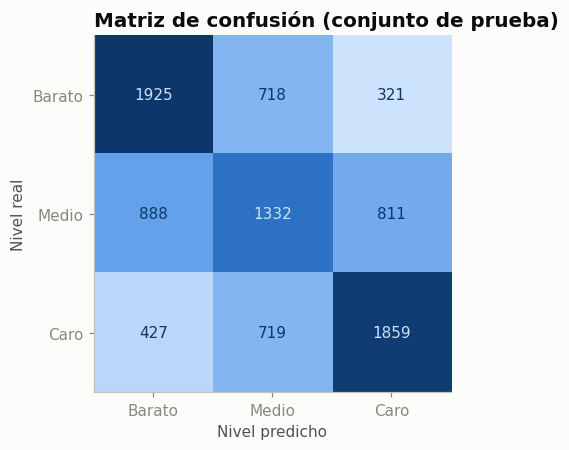

In [ ]:
# 5.4 Matriz de confusión: filas = nivel real, columnas = nivel que predijo la red
etiquetas = NIVELES
cm = confusion_matrix(y_te, pred, labels=[0, 1, 2])   # cuenta cuántos productos hay en cada combinación real/predicho
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ConfusionMatrixDisplay(cm, display_labels=etiquetas).plot(ax=ax, cmap=SEC, colorbar=False, values_format="d")   # "d" = números enteros
ax.grid(False); ax.set_xlabel("Nivel predicho"); ax.set_ylabel("Nivel real")
ax.set_title("Matriz de confusión (conjunto de prueba)")
plt.tight_layout(); plt.show()

Cada fila representa el nivel de precio real y cada columna, el nivel que predijo la red.
- La **diagonal** (arriba-izquierda a abajo-derecha) son los aciertos.
- Los errores **al lado de la diagonal** son confusiones entre niveles vecinos (Barato↔Medio, Medio↔Caro): son errores "chicos".
- Los errores **en las esquinas** (Barato↔Caro) son los graves. Si casi no hay, la red **se equivoca "cerca"**.
- Es lógico que cueste en el medio: los cortes entre niveles son **artificiales**, y un producto de 17 dólares se parece mucho a uno de 18.

### 5.5 ¿Qué información pesa más? (importancia por permutación)
En este paso medimos cuánto baja el accuracy de la red cuando mezclamos al azar los valores de una variable entre los productos de prueba. Repetimos el procedimiento cinco veces por variable para que el resultado no dependa tanto de una sola mezcla. Todas las palabras del título se mezclan juntas, como un único bloque.

Esto permite entender qué información utiliza más la red para hacer sus predicciones. Como una red neuronal no muestra reglas fáciles de interpretar, esta técnica nos ayuda a analizar su funcionamiento.

Si al mezclar una variable el accuracy baja mucho, significa que la red dependía bastante de esa información. En cambio, si casi no cambia, esa variable aporta poco a sus predicciones. Es una forma de estimar la importancia de cada variable para el modelo, aunque no demuestra que exista una relación de causa y efecto.

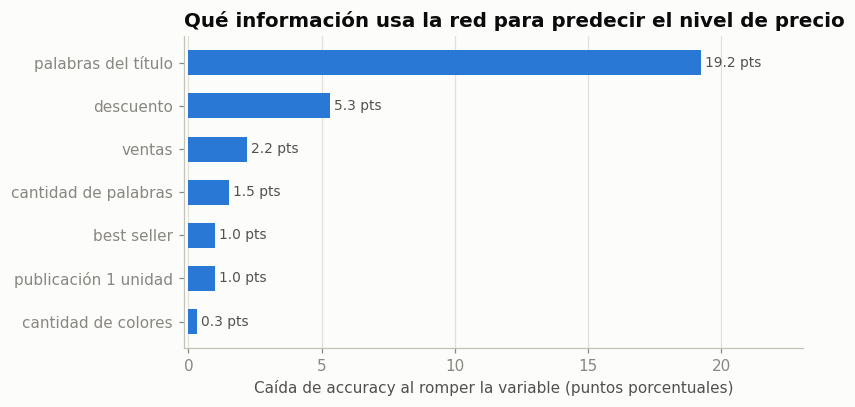

In [ ]:
# 5.5 Importancia por permutación: mezclamos al azar una variable por vez y medimos cuánto cae el accuracy
# (si cae mucho, la red dependía mucho de esa variable). n_repeats=5: se repite 5 veces y se promedia
rep = permutation_importance(red, X_te, y_te, n_repeats=5, random_state=SEED, scoring="accuracy")
nombres_imp = {"nombre": "palabras del título", "descuento": "descuento", "log_vendidos": "ventas",
               "es_bestseller": "best seller", "es_1pc": "publicación 1 unidad", "colores": "cantidad de colores", "n_palabras": "cantidad de palabras"}
imp = pd.Series(rep.importances_mean, index=[nombres_imp[c] for c in X_te.columns]).sort_values()   # caída promedio por variable

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(imp.index, imp.values * 100, color=AZUL, height=0.58)   # *100: pasamos a puntos porcentuales
for y_, v in enumerate(imp.values * 100):                       # valor escrito al lado de cada barra
    ax.text(max(v, 0) + 0.15, y_, f"{v:.1f} pts", va="center", fontsize=9, color="#52514e")
ax.set_xlim(min(0, imp.min() * 100 - 0.5), imp.max() * 100 * 1.2)
ax.set_xlabel("Caída de accuracy al romper la variable (puntos porcentuales)")
ax.set_title("Qué información usa la red para predecir el nivel de precio")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Cada barra muestra cuántos puntos de accuracy pierde la red cuando se mezclan los valores de una variable. Cuanto más larga es la barra, más depende el modelo de esa información para hacer sus predicciones.

Si una barra está cerca de cero, significa que alterar esa variable casi no afecta el resultado. Esto puede indicar que aporta poco o que la información que contiene ya está presente en otras variables.

Hay que tener en cuenta que algunas variables pueden aportar información similar. En esos casos, la red puede apoyarse en una para compensar la pérdida de la otra, por lo que la importancia individual de cada una puede parecer menor de lo que realmente es en conjunto.

### 5.6 ¿Qué tamaño de red conviene? (control de sobreajuste)
Entrenamos cuatro redes neuronales de distintos tamaños y comparamos su accuracy tanto en los datos de entrenamiento como en los de prueba.

El objetivo es comprobar si aumentar el tamaño de la red mejora las predicciones. Una red más grande puede aprender relaciones más complejas, pero también corre el riesgo de memorizar los ejemplos con los que entrenó y rendir peor con productos nuevos.

Por eso, buscamos un tamaño que consiga buenos resultados en los datos de prueba sin que haya una diferencia demasiado grande respecto del entrenamiento. Es una forma de encontrar un equilibrio entre la capacidad de aprendizaje de la red y su capacidad para generalizar.

,entrenamiento,prueba
red,,
1 capa\n4 neuronas,55.6,53.4
1 capa\n32 neuronas,68.1,57.3
2 capas\n64-32,70.9,56.8
3 capas\n128-64-32,59.8,55.8


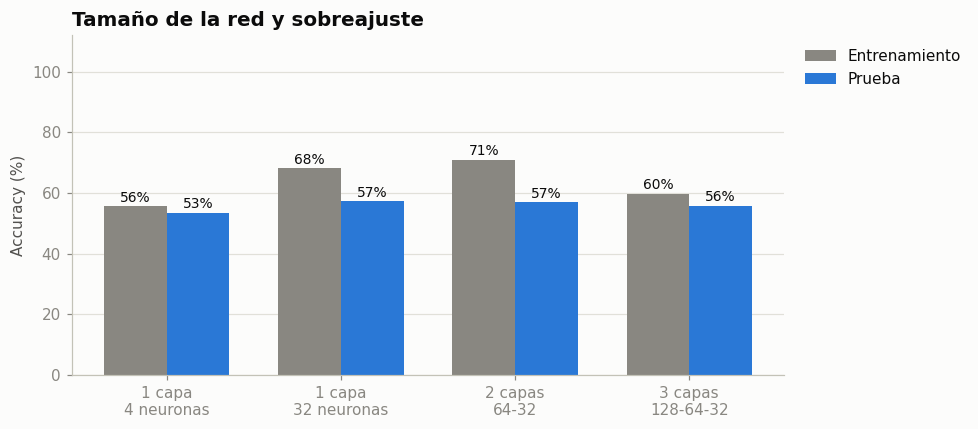

In [ ]:
# 5.6 Comparamos 4 tamaños de red para controlar el sobreajuste
# Clave: rótulo para el gráfico | valor: neuronas por capa oculta
arqs = {"1 capa\n4 neuronas": (4,), "1 capa\n32 neuronas": (32,), "2 capas\n64-32": (64, 32), "3 capas\n128-64-32": (128, 64, 32)}
filas = []
for nombre, capas in arqs.items():                     # entrenamos una red de cada tamaño y guardamos su accuracy
    r = armar_red(capas=capas).fit(X_tr, y_tr)
    filas.append({"red": nombre, "entrenamiento": r.score(X_tr, y_tr) * 100, "prueba": r.score(X_te, y_te) * 100})
comp = pd.DataFrame(filas).set_index("red")
display(comp.round(1))

# Barras agrupadas: gris = entrenamiento, azul = prueba (si la gris es mucho más alta, hay sobreajuste)
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(comp)); w = 0.36                     # posición de cada grupo y ancho de cada barra
ax.bar(x - w/2, comp["entrenamiento"], w, color=GRIS, label="Entrenamiento")
ax.bar(x + w/2, comp["prueba"], w, color=AZUL, label="Prueba")
for i, (a, b) in enumerate(zip(comp["entrenamiento"], comp["prueba"])):   # % arriba de cada barra
    ax.text(i - w/2, a + 1.5, f"{a:.0f}%", ha="center", fontsize=9); ax.text(i + w/2, b + 1.5, f"{b:.0f}%", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(comp.index)
ax.set_ylim(0, 112); ax.set_ylabel("Accuracy (%)"); ax.set_title("Tamaño de la red y sobreajuste")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Para cada tamaño de red aparecen dos barras: la gris representa el accuracy sobre los productos de entrenamiento, que la red ya vio, y la azul muestra el resultado con los productos de prueba, que son nuevos para ella.
- Si la red es muy chica, **ambas son bajas**: no alcanza para captar el patrón (*subajuste*).
- Si crece y la barra gris sube pero la azul **no acompaña**, la red está **memorizando** (*sobreajuste*): la distancia entre las dos barras es la señal.
- Nos conviene la red cuya barra azul sea la **más alta o similar a las demás con la menor brecha**. Si varias dan parecido, es preferible la más simple.
- Ojo: con pocos datos, el resultado de cada red **varía un poco** según cómo arranca (pesos iniciales al azar) y cuándo frena el *early stopping*. Diferencias de 1 o 2 puntos **no son significativas**.

### 5.7 Segundo caso: ¿qué aporta cada tipo de información?
En este paso entrenamos tres redes neuronales con distintos datos de entrada. La primera usa solo las variables comerciales (descuento, ventas, Best Seller, publicación de una unidad, cantidad de colores y cantidad de palabras). La segunda utiliza únicamente las palabras de los títulos, mientras que la tercera combina toda la información.

La idea es comparar los resultados para ver si el nivel de precio se puede predecir mejor a partir de los títulos o de las variables comerciales, y comprobar si combinar ambas fuentes mejora las predicciones. Así podemos evaluar qué aporta cada tipo de información al modelo.

A) Solo variables\ncomerciales    44.9
B) Solo palabras\ndel título      53.5
C) Todo junto                     56.8


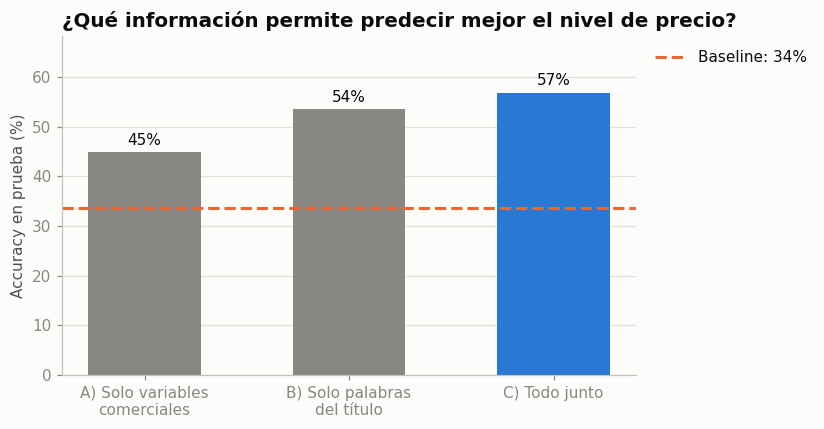

In [ ]:
# 5.7 ¿Qué aporta cada tipo de información? Entrenamos 3 redes con distintas entradas
casos = {"A) Solo variables\ncomerciales": dict(num=NUM, texto=False),   # sin palabras del título
         "B) Solo palabras\ndel título": dict(num=[], texto=True),        # sin variables numéricas
         "C) Todo junto": dict(num=NUM, texto=True)}                      # las dos cosas
res = {}
for nombre, cfg in casos.items():
    r = armar_red(**cfg).fit(X_tr, y_tr)               # **cfg pasa num=... y texto=... a la función
    res[nombre] = r.score(X_te, y_te) * 100            # accuracy en prueba
azar = base.score(X_te, y_te) * 100                    # accuracy del baseline, como referencia
print(pd.Series(res).round(1).to_string())

fig, ax = plt.subplots(figsize=(7.6, 4))
ax.bar(list(res), list(res.values()), color=[GRIS, GRIS, AZUL], width=0.55)   # el caso C resaltado en azul
for i, v in enumerate(res.values()):
    ax.text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=10)
ax.axhline(azar, color=NARANJA, linestyle="--", label=f"Baseline: {azar:.0f}%")   # línea del baseline
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_ylim(0, max(res.values()) * 1.2); ax.set_ylabel("Accuracy en prueba (%)")
ax.set_title("¿Qué información permite predecir mejor el nivel de precio?")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Cada barra muestra el accuracy obtenido con un conjunto distinto de información, mientras que la línea naranja representa el baseline, es decir, el resultado de predecir siempre la clase más frecuente.
- Comparalas con el baseline: una barra apenas por encima casi **no aporta** información sobre el precio.
- Si **B** (solo texto) está cerca de **C** (todo), el título lleva casi toda la información. Si **A** (comerciales) queda muy abajo, esas variables solas **no alcanzan**.
- Si **C** supera a **B**, las variables comerciales **suman** algo al texto.
- Esto responde la pregunta del trabajo: *¿qué distingue a un producto caro de uno barato?* En esta tienda, lo que se **dice del producto** (el título) pesa más o menos que **cómo se vende** (descuento, ventas).

## 6. Conclusiones

Conclusión
A lo largo del trabajo, analizamos los productos de SHEIN para encontrar patrones en sus precios y características de publicación. Primero, limpiamos y organizamos los datos, ya que había valores faltantes, duplicados e inconsistencias. Después, realizamos distintas visualizaciones para conocer mejor los precios, los descuentos, las ventas y las diferencias entre categorías.

Con K-Means, agrupamos los productos según características como el precio relativo a su categoría, los descuentos, las ventas y la cantidad de palabras del título. Luego, analizamos los grupos para entender qué los diferenciaba. Esto nos permitió evaluar si los clusters reunían productos con características comerciales similares o si estaban relacionados principalmente con el nivel de precio o el tipo de producto.

Por otro lado, utilizamos una red neuronal para predecir si un producto era Barato, Medio o Caro dentro de su categoría, sin incluir el precio ni la categoría entre los datos de entrada. Comparamos su rendimiento con un modelo de referencia y probamos distintas configuraciones y conjuntos de variables. También analizamos sus errores y la importancia de la información utilizada para realizar las predicciones.

En conjunto, estos experimentos permiten estudiar qué características se relacionan con el nivel de precio y hasta qué punto se puede predecir utilizando información disponible en las publicaciones. Comparar los títulos con las variables comerciales ayuda a evaluar qué aporta cada tipo de información. Sin embargo, las predicciones no son perfectas y las relaciones encontradas no implican necesariamente una causa directa.

Por último, es importante tener en cuenta que trabajamos con una muestra de productos y con datos obtenidos de SHEIN, que pueden contener limitaciones o no representar toda la tienda. Por eso, los resultados describen los patrones encontrados en estos datos y no deben tomarse como una regla general para todos los productos o comercios.

### Resumen de resultados
| Pregunta | Resultado |
|---|---|
| ¿Cuántos productos usamos tras la limpieza? | 66.350 de 77.486 (se descartó `swimwear` por no tener ventas, se eliminaron 7.364 duplicados —10%— y 1 registro con precio falso de 888.888 dólares) |
| ¿Hubo valores imposibles? | Un registro de prueba (precio 888.888 con título falso); el resto, ningún valor fuera de rango |
| Precio mediano de toda la tienda | 5,30 dólares (de 0,15 a 2.399,99); varía mucho por categoría: de 2 (joyería) a 17 (electrodomésticos) |
| K-Means: K elegido y silueta | K = 5, silueta 0,31 (estructura moderada) |
| K-Means: pureza respecto del nivel de precio | 48% (sin criterio sería 34%) |
| Red neuronal: accuracy en prueba | 56,3% (baseline 33,6%) · F1 macro 0,560 |
| Red neuronal: validación cruzada (3 folds) | 56,9% ± 0,1% |
| Información que más usa la red | Palabras del título (−17,6 puntos de accuracy si se las rompe), luego descuento (5,1), ventas (2,2) y publicación de 1 unidad (2,2) |
| Solo variables comerciales / solo palabras / todo | 44,9% / 50,8% / 56,3% |

### Principales resultados del análisis
¿Qué grupos aparecen con K-Means y cómo se relacionan con las categorías?

K-Means formó cinco grupos con una silueta de 0,31, lo que indica una separación moderada entre ellos. Los grupos se superponen y no tienen límites muy definidos. Se diferencian por una combinación de precio relativo, descuentos, ventas y largo de los títulos.

Cluster 1 — Productos baratos con grandes descuentos (15%): el precio típico equivale a 0,54 veces el de su categoría. El 100% tiene descuento y el 68% pertenece al nivel Barato.

Cluster 2 — Productos con ventas visibles (46%): todos muestran una etiqueta de ventas, ninguno es Best Seller y sus precios son típicos de sus categorías. Es el grupo más grande y reúne principalmente productos de ropa, niños, bebés y joyería.

Cluster 3 — Productos con títulos largos (9%): los títulos tienen unas 35 palabras, frente a las 13 a 21 del resto de los grupos. También muestran ventas visibles y aparecen principalmente en bolsos, equipaje y belleza.

Cluster 4 — Productos en el ranking y sin ventas visibles (23%): el 58% es Best Seller y solo el 10% muestra ventas. Tiene una presencia destacada en electrodomésticos, ropa interior, ropa de hombre y calzado.

Cluster 5 — Productos de precio elevado (8%): su precio típico equivale a siete veces el de su categoría y el 100% pertenece al nivel Caro. Aparece con mayor frecuencia en herramientas, electrodomésticos, automotor y mascotas, especialmente en muebles y equipos grandes.

Los grupos atraviesan las distintas categorías: todas aparecen en los cinco clusters, aunque en diferentes proporciones. La pureza respecto del nivel de precio es del 48%, frente al 34% que se obtiene tomando como referencia la clase más frecuente. Esto muestra que los grupos tienen relación con el precio, pero también se diferencian por cómo se publican los productos, por ejemplo, mediante los descuentos, las ventas visibles y el ranking.

¿Se puede predecir el nivel de precio sin utilizar el precio como dato de entrada?

Sí, aunque con ciertas limitaciones. La red neuronal acierta el 56,3% de los productos de prueba, mientras que el modelo de referencia alcanza el 33,6%. En la validación cruzada obtiene un resultado similar, del 56,9%. Esto indica que puede aprender patrones útiles, aunque sus predicciones todavía tienen margen de mejora.

La red tiene más dificultades para clasificar los productos de nivel Medio: su F1 es de 0,44, frente a 0,61 para Barato y 0,63 para Caro. Esto puede deberse, en parte, a que los límites entre los niveles son divisiones definidas para el trabajo y algunos productos tienen precios similares, pero pertenecen a clases distintas.

Al analizar qué información utiliza, las palabras de los títulos son las que más influyen: al mezclarlas al azar, el accuracy cae casi 18 puntos. El descuento aporta una caída de unos 5 puntos y las ventas, de unos 2. La comparación entre distintos conjuntos de datos confirma esta diferencia: usando solo el texto se obtiene un 50,8% de accuracy; con las variables comerciales, un 44,9%; y combinando ambas, un 56,3%. Por lo tanto, las dos fuentes aportan información, pero el título tiene mayor peso en las predicciones.

¿Qué características diferencian a los productos caros de los baratos dentro de su categoría?

Las variables comerciales muestran diferencias relativamente pequeñas entre los tres niveles de precio. El porcentaje de productos con descuento es del 69% en Barato, 63% en Medio y 66% en Caro. Lo mismo ocurre con los Best Sellers: representan el 17%, 18% y 17%, respectivamente. En cambio, las ventas visibles disminuyen en los productos caros: aparecen en el 74% de los baratos, el 72% de los medios y el 61% de los caros.

La correlación entre el precio relativo y las ventas es de apenas −0,06, por lo que no se observa una relación clara entre el precio de un producto respecto de su categoría y sus ventas.

En los títulos sí aparecen diferencias más marcadas. Palabras como shoulder, large, high, long, office, set, dress y bag se asocian con productos cuyo precio es entre 1,2 y 1,4 veces el valor típico de su categoría. En cambio, términos como birthday, decoration, DIY, cartoon, cute, accessories y supplies se relacionan con productos cuyo precio ronda 0,8 veces ese valor.

En estos datos, las palabras relacionadas con el tamaño y la funcionalidad aparecen más asociadas a precios elevados, mientras que las vinculadas con decoración y accesorios se relacionan con precios más bajos. Esto describe asociaciones encontradas en los títulos, no necesariamente causas directas del precio.

### Observaciones sobre el dato
En todo el conjunto, ningún producto tiene al mismo tiempo la etiqueta Best Seller y una etiqueta de ventas visibles. Esto indica que son excluyentes en los datos analizados y que no representan dos señales independientes de popularidad. Su correlación es de −0,56, y esta característica de la tienda explica en parte la formación del Cluster 4.

La red más pequeña, de una capa y cuatro neuronas, alcanza un 54,3% de accuracy en prueba, mientras que las más grandes rondan el 56-57%. Las diferencias de uno o dos puntos no son suficientes para afirmar que una arquitectura es mejor que otra. En la red de dos capas (64 y 32 neuronas), el accuracy es del 70,4% en entrenamiento y del 56,3% en prueba. Esta diferencia muestra que existe sobreajuste, aunque se intenta reducir mediante early stopping.

Al analizar solamente la categoría Appliances, la red alcanzaba aproximadamente un 72% de accuracy, ya que las palabras del título permitían distinguir productos muy diferentes, como un mini ventilador y una heladera. Al incluir 19 categorías y definir los niveles de precio dentro de cada una, esa diferencia entre tipos de productos deja de ser tan útil y la predicción se vuelve más difícil. En ese caso, el resultado es del 56%.

### Limitaciones (para mencionar en la defensa)
Excluimos la categoría swimwear porque su archivo no incluye la columna de ventas. Además, automotive y baby and maternity no tienen información de ranking, por lo que es_bestseller = 0 en esas categorías significa que no hay datos disponibles, no necesariamente que el producto no sea Best Seller.

Los datos representan el momento en que se recopilaron. Los precios, descuentos y rankings pueden cambiar con el tiempo.

La variable vendidos muestra cantidades aproximadas por tramos, como «400+ sold recently», y solo aparece a partir de las 10 ventas. Los valores faltantes de ventas, descuentos y colores se trataron como cero, una decisión que puede afectar los resultados.

Los niveles Barato, Medio y Caro fueron definidos para este trabajo mediante terciles dentro de cada categoría. No son clasificaciones oficiales de SHEIN.

Establecimos un límite de 10.000 dólares para el precio, que permitió eliminar un único registro falso.

Eliminamos duplicados según el título y el precio. Si un producto tenía el mismo título, pero otro precio, lo conservamos. Si aparecía en varias categorías, dejamos una sola versión, priorizando la que tenía más información.

El conjunto de datos no incluye calificaciones, reseñas, marcas ni características técnicas, que podrían ayudar a explicar mejor las diferencias de precio.

Para entrenar los modelos utilizamos una muestra de 30.000 productos, con el objetivo de reducir los tiempos de ejecución en Colab. Los gráficos exploratorios, en cambio, utilizan todos los productos limpios.

La red neuronal funciona como una caja negra: la importancia por permutación permite observar qué variables influyen más en las predicciones, pero no explica exactamente cómo las combina para llegar a un resultado.

### Posibles mejoras
Una mejora sería incorporar una tercera técnica de la consigna, como un mapa autoorganizado (SOM) para visualizar los segmentos o redes bayesianas para estudiar las relaciones entre descuentos, ventas y precios. También se podría extraer información sobre la subcategoría o la marca a partir de los títulos, predecir el precio como un valor numérico en lugar de dividirlo en tres niveles y analizar cada categoría por separado para comprobar si las palabras de los títulos tienen la misma importancia en todas ellas.